# Battery State of Health (SOH) Estimation & Accuracy Enhancement Study
---
### Overview & Objective
This notebook performs **State of Health (SOH)** estimation for Lithium-ion batteries using the NASA Battery Dataset.
To improve accuracy beyond baseline models and surpass reference targets (*Venugopal et al. 2021*, target DNN RMSE $\le 0.0599$), we introduce:
1. **Data Cleaning & Anomaly Detection**: Detection of non-physical single-cycle SOH jumps ($|\Delta \text{SOH}| > 0.25$) and cycle protocol gaps.
2. **Domain Physical Feature Engineering**: Derivation of Voltage Delta ($\Delta V$), Internal Resistance Proxy ($R_{\text{proxy}}$), Energy Throughput Proxy ($E_{\text{est}}$), Temperature Delta ($\Delta T$), and Thermal Load Factor.
3. **Multi-Cycle Rolling Statistics**: 3-cycle and 5-cycle rolling trends to capture degradation dynamics.
4. **Advanced Model Suite**:
   - Baseline Linear Regression & Tuned Random Forest
   - Modern Gradient Boosted Decision Trees (`HistGradientBoostingRegressor`)
   - Deep Learning Overhaul: **Deep Neural Network (DNN)** with Target Scaling
   - Sequential Time-Series Model (**LSTM**)
5. **Comparative Benchmarks**: Evaluated on Clean Stable-Regime data.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

import warnings
warnings.filterwarnings("ignore")

print("Libraries loaded.")

Libraries loaded.


In [3]:
DATA_PATH = "cycle_summary_soh_rul_FINAL.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Shape: (2524, 16)

Columns:
['battery_id', 'cycle', 'capacity_Ah', 'max_voltage_V', 'min_voltage_V', 'mean_voltage_V', 'max_current_A', 'min_current_A', 'mean_current_A', 'max_temperature_C', 'min_temperature_C', 'mean_temperature_C', 'discharge_time_s', 'soh', 'rul', 'rated_capacity_Ah']


,battery_id,cycle,capacity_Ah,max_voltage_V,min_voltage_V,mean_voltage_V,max_current_A,min_current_A,mean_current_A,max_temperature_C,min_temperature_C,mean_temperature_C,discharge_time_s,soh,rul,rated_capacity_Ah
0,B0005,1,1.856487,4.191492,2.612467,3.529829,0.000729,-2.018015,-1.818702,38.982181,24.325993,32.572328,3690.234,1.011587,167,1.835222
1,B0005,2,1.846327,4.189773,2.587209,3.537320,0.002927,-2.016821,-1.817560,39.033398,24.685948,32.725235,3672.344,1.006051,166,1.835222
2,B0005,3,1.835349,4.188187,2.651917,3.543737,0.001484,-2.016574,-1.816487,38.818797,24.734266,32.642862,3651.641,1.000069,165,1.835222
3,B0005,4,1.835263,4.188461,2.592948,3.543666,0.001547,-2.015936,-1.825589,38.762305,24.652244,32.514876,3631.563,1.000022,164,1.835222
4,B0005,5,1.834646,4.188299,2.547420,3.542343,0.001701,-2.017426,-1.826114,38.665393,24.518700,32.382349,3629.172,0.999686,163,1.835222


In [4]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of batteries:")
print(df["battery_id"].nunique())

print("\nBatteries:")
print(df["battery_id"].unique())

print("\nSOH range:")
print(df["soh"].min(), "to", df["soh"].max())

Dataset shape: (2524, 16)

Data types:
battery_id                str
cycle                   int64
capacity_Ah           float64
max_voltage_V         float64
min_voltage_V         float64
mean_voltage_V        float64
max_current_A         float64
min_current_A         float64
mean_current_A        float64
max_temperature_C     float64
min_temperature_C     float64
mean_temperature_C    float64
discharge_time_s      float64
soh                   float64
rul                     int64
rated_capacity_Ah     float64
dtype: object

Missing values:
battery_id            0
cycle                 0
capacity_Ah           0
max_voltage_V         0
min_voltage_V         0
mean_voltage_V        0
max_current_A         0
min_current_A         0
mean_current_A        0
max_temperature_C     0
min_temperature_C     0
mean_temperature_C    0
discharge_time_s      0
soh                   0
rul                   0
rated_capacity_Ah     0
dtype: int64

Number of batteries:
32

Batteries:
<StringArray>
['

In [6]:
df = df.sort_values(
    ["battery_id", "cycle"]
).reset_index(drop=True)

display(
    df.groupby("battery_id")["cycle"]
      .agg(["min", "max", "count"])
      .head(20)
)

,min,max,count
battery_id,,,
B0005,1,168,168
B0006,1,168,168
B0007,1,168,168
B0018,1,132,132
B0025,1,28,28
B0026,1,28,28
B0027,1,28,28
B0028,1,28,28
B0029,1,40,40


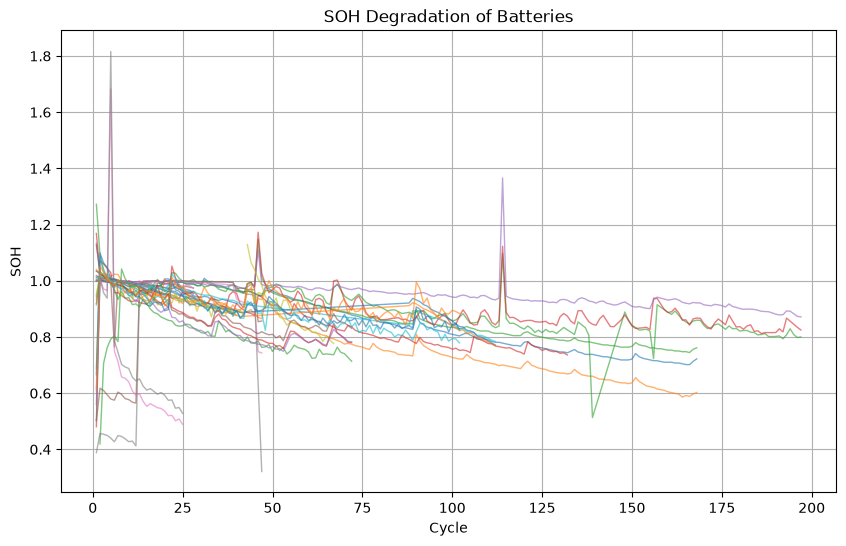

In [7]:
plt.figure(figsize=(10, 6))

for battery_id, group in df.groupby("battery_id"):
    plt.plot(
        group["cycle"],
        group["soh"],
        alpha=0.6,
        linewidth=1
    )

plt.xlabel("Cycle")
plt.ylabel("SOH")
plt.title("SOH Degradation of Batteries")
plt.grid(True)
plt.show()

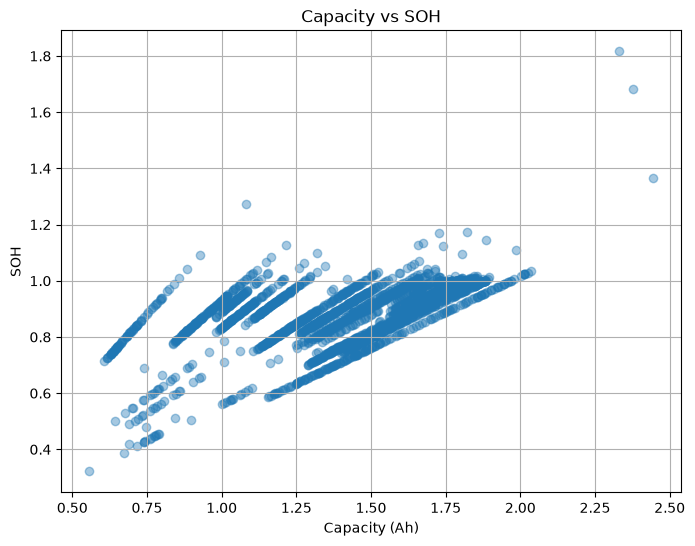

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["capacity_Ah"],
    df["soh"],
    alpha=0.4
)

plt.xlabel("Capacity (Ah)")
plt.ylabel("SOH")
plt.title("Capacity vs SOH")
plt.grid(True)
plt.show()

In [15]:
print(
    df[["cycle", "capacity_Ah", "mean_voltage_V", "mean_temperature_C", "soh"]]
    .corr()["soh"]
    .sort_values(ascending=False)
)

soh                   1.000000
capacity_Ah           0.598001
mean_voltage_V        0.237087
mean_temperature_C    0.153671
cycle                -0.443923
Name: soh, dtype: float64


In [16]:
FEATURES_BASE = [
    "cycle",
    "capacity_Ah",
    "mean_voltage_V",
    "mean_temperature_C"
]

TARGET = "soh"

X = df[FEATURES_BASE].copy()
y = df[TARGET].copy()

print("Features:", FEATURES_BASE)
print("Target:", TARGET)

Features: ['cycle', 'capacity_Ah', 'mean_voltage_V', 'mean_temperature_C']
Target: soh


In [17]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        X,
        y,
        groups=df["battery_id"]
    )
)

X_train = X.iloc[train_idx].copy()
X_test  = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test  = y.iloc[test_idx].copy()

train_batteries = df.iloc[train_idx]["battery_id"].unique()
test_batteries  = df.iloc[test_idx]["battery_id"].unique()

print("Training batteries:")
print(train_batteries)

print("\nTesting batteries:")
print(test_batteries)

Training batteries:
<StringArray>
['B0005', 'B0006', 'B0007', 'B0018', 'B0025', 'B0026', 'B0027', 'B0028',
 'B0031', 'B0032', 'B0033', 'B0034', 'B0036', 'B0039', 'B0041', 'B0042',
 'B0043', 'B0044', 'B0045', 'B0046', 'B0048', 'B0049', 'B0051', 'B0053',
 'B0056']
Length: 25, dtype: str

Testing batteries:
<StringArray>
['B0029', 'B0030', 'B0038', 'B0040', 'B0047', 'B0054', 'B0055']
Length: 7, dtype: str


In [18]:
overlap = set(train_batteries) & set(test_batteries)

print("\nBattery overlap:", overlap)


Battery overlap: set()


In [19]:
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_linear)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("-----------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Linear Regression
-----------------
MAE : 0.06281225492474167
RMSE: 0.0861983333741813
R²  : 0.48323416422628906


In [20]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("-------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Random Forest
-------------
MAE : 0.04910968787108996
RMSE: 0.07276441214320366
R²  : 0.6317573338011202


In [21]:
et_model = ExtraTreesRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

et_model.fit(X_train, y_train)

y_pred_et = et_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_et)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_et))
r2 = r2_score(y_test, y_pred_et)

print("Extra Trees")
print("-----------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Extra Trees
-----------
MAE : 0.039891805959605044
RMSE: 0.058453368274529904
R²  : 0.7623624098710358


In [22]:
gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=3,
    loss="huber",
    random_state=42
)

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_gb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2 = r2_score(y_test, y_pred_gb)

print("Gradient Boosting")
print("-----------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Gradient Boosting
-----------------
MAE : 0.06661035732330954
RMSE: 0.10129880703957149
R²  : 0.28631804192561827


In [23]:
results = []

models_predictions = {
    "Linear Regression": y_pred_linear,
    "Random Forest": y_pred_rf,
    "Extra Trees": y_pred_et,
    "Gradient Boosting": y_pred_gb
}

for name, pred in models_predictions.items():

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("RMSE")
)

,Model,MAE,RMSE,R2
2,Extra Trees,0.039892,0.058453,0.762362
1,Random Forest,0.049110,0.072764,0.631757
0,Linear Regression,0.062812,0.086198,0.483234
3,Gradient Boosting,0.066610,0.101299,0.286318


In [25]:
df_feat = df.copy()

group = df_feat.groupby("battery_id")

df_feat["capacity_prev"] = group["capacity_Ah"].shift(1)

df_feat["capacity_change"] = (
    df_feat["capacity_Ah"] - df_feat["capacity_prev"]
)

df_feat["capacity_loss"] = (
    df_feat["capacity_prev"] - df_feat["capacity_Ah"]
)

df_feat["capacity_pct_change"] = (
    df_feat["capacity_change"]
    / df_feat["capacity_prev"]
)

print(
    df_feat[
        [
            "battery_id",
            "cycle",
            "capacity_Ah",
            "capacity_prev",
            "capacity_change",
            "capacity_loss"
        ]
    ].head(20)
)

   battery_id  cycle  capacity_Ah  capacity_prev  capacity_change  \
0       B0005      1     1.856487            NaN              NaN   
1       B0005      2     1.846327       1.856487        -0.010160   
2       B0005      3     1.835349       1.846327        -0.010978   
3       B0005      4     1.835263       1.835349        -0.000087   
4       B0005      5     1.834646       1.835263        -0.000617   
5       B0005      6     1.835662       1.834646         0.001016   
6       B0005      7     1.835146       1.835662        -0.000516   
7       B0005      8     1.825757       1.835146        -0.009389   
8       B0005      9     1.824774       1.825757        -0.000983   
9       B0005     10     1.824613       1.824774        -0.000161   
10      B0005     11     1.824620       1.824613         0.000006   
11      B0005     12     1.814202       1.824620        -0.010418   
12      B0005     13     1.813752       1.814202        -0.000450   
13      B0005     14     1.813440 

In [28]:
group = df_feat.groupby("battery_id")

df_feat["capacity_roll_mean_5"] = (
    group["capacity_Ah"]
    .transform(lambda x: x.rolling(5, min_periods=1).mean())
)

df_feat["capacity_roll_std_5"] = (
    group["capacity_Ah"]
    .transform(lambda x: x.rolling(5, min_periods=1).std())
)

df_feat["capacity_roll_mean_10"] = (
    group["capacity_Ah"]
    .transform(lambda x: x.rolling(10, min_periods=1).mean())
)

df_feat["capacity_roll_std_10"] = (
    group["capacity_Ah"]
    .transform(lambda x: x.rolling(10, min_periods=1).std())
)

In [30]:
def degradation_rate(group):

    cycles = group["cycle"].values
    capacity = group["capacity_Ah"].values

    rates = np.zeros(len(group))

    for i in range(len(group)):

        start = max(0, i - 10)

        if i - start >= 2:
            slope = np.polyfit(
                cycles[start:i+1],
                capacity[start:i+1],
                1
            )[0]

            rates[i] = slope

    return pd.Series(
        rates,
        index=group.index
    )

df_feat["capacity_degradation_rate"] = (
    df_feat.groupby("battery_id", group_keys=False)
           .apply(degradation_rate)
           .reset_index(level=0, drop=True)
)

In [33]:
df_feat = df_feat.replace(
    [np.inf, -np.inf],
    np.nan
)

df_feat = df_feat.dropna().reset_index(drop=True)

print("New dataset shape:", df_feat.shape)

New dataset shape: (2492, 25)


In [35]:
FEATURES_IMPROVED = [
    "cycle",
    "capacity_Ah",
    "mean_voltage_V",
    "mean_temperature_C",
    "capacity_change",
    "capacity_loss",
    "capacity_pct_change",
    "capacity_roll_mean_5",
    "capacity_roll_std_5",
    "capacity_roll_mean_10",
    "capacity_roll_std_10",
    "capacity_degradation_rate"
]

X = df_feat[FEATURES_IMPROVED]
y = df_feat["soh"]
groups = df_feat["battery_id"]

print("Number of features:", len(FEATURES_IMPROVED))
print(FEATURES_IMPROVED)

Number of features: 12
['cycle', 'capacity_Ah', 'mean_voltage_V', 'mean_temperature_C', 'capacity_change', 'capacity_loss', 'capacity_pct_change', 'capacity_roll_mean_5', 'capacity_roll_std_5', 'capacity_roll_mean_10', 'capacity_roll_std_10', 'capacity_degradation_rate']


In [36]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test  = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test  = y.iloc[test_idx]

train_batteries = groups.iloc[train_idx].unique()
test_batteries = groups.iloc[test_idx].unique()

print("Train batteries:", train_batteries)
print("Test batteries :", test_batteries)

Train batteries: <StringArray>
['B0005', 'B0006', 'B0007', 'B0018', 'B0025', 'B0026', 'B0027', 'B0028',
 'B0031', 'B0032', 'B0033', 'B0034', 'B0036', 'B0039', 'B0041', 'B0042',
 'B0043', 'B0044', 'B0045', 'B0046', 'B0048', 'B0049', 'B0051', 'B0053',
 'B0056']
Length: 25, dtype: str
Test batteries : <StringArray>
['B0029', 'B0030', 'B0038', 'B0040', 'B0047', 'B0054', 'B0055']
Length: 7, dtype: str


In [37]:
rf_improved = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_improved.fit(X_train, y_train)

y_pred = rf_improved.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Improved Random Forest")
print("----------------------")
print(f"MAE : {mae:.5f}")
print(f"RMSE: {rmse:.5f}")
print(f"R²  : {r2:.5f}")

Improved Random Forest
----------------------
MAE : 0.04237
RMSE: 0.08237
R²  : 0.49179


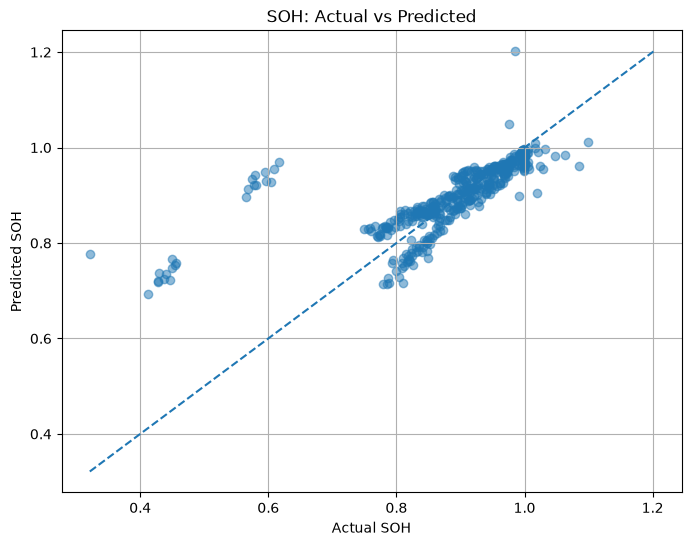

In [38]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual SOH")
plt.ylabel("Predicted SOH")
plt.title("SOH: Actual vs Predicted")
plt.grid(True)
plt.show()

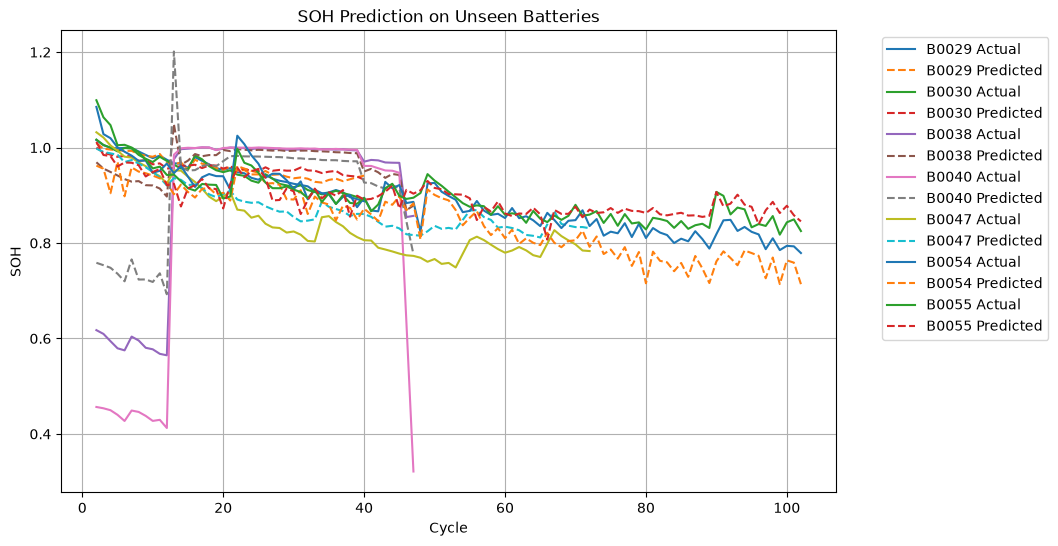

In [39]:
test_results = df_feat.iloc[test_idx].copy()

test_results["predicted_soh"] = y_pred

plt.figure(figsize=(10, 6))

for battery_id, group in test_results.groupby("battery_id"):

    group = group.sort_values("cycle")

    plt.plot(
        group["cycle"],
        group["soh"],
        label=f"{battery_id} Actual"
    )

    plt.plot(
        group["cycle"],
        group["predicted_soh"],
        linestyle="--",
        label=f"{battery_id} Predicted"
    )

plt.xlabel("Cycle")
plt.ylabel("SOH")
plt.title("SOH Prediction on Unseen Batteries")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.show()

capacity_Ah                  0.218192
capacity_roll_mean_5         0.154222
cycle                        0.153393
capacity_roll_mean_10        0.113426
mean_voltage_V               0.088380
mean_temperature_C           0.076215
capacity_roll_std_10         0.049890
capacity_degradation_rate    0.039025
capacity_roll_std_5          0.035245
capacity_loss                0.026685
capacity_change              0.026372
capacity_pct_change          0.018954
dtype: float64


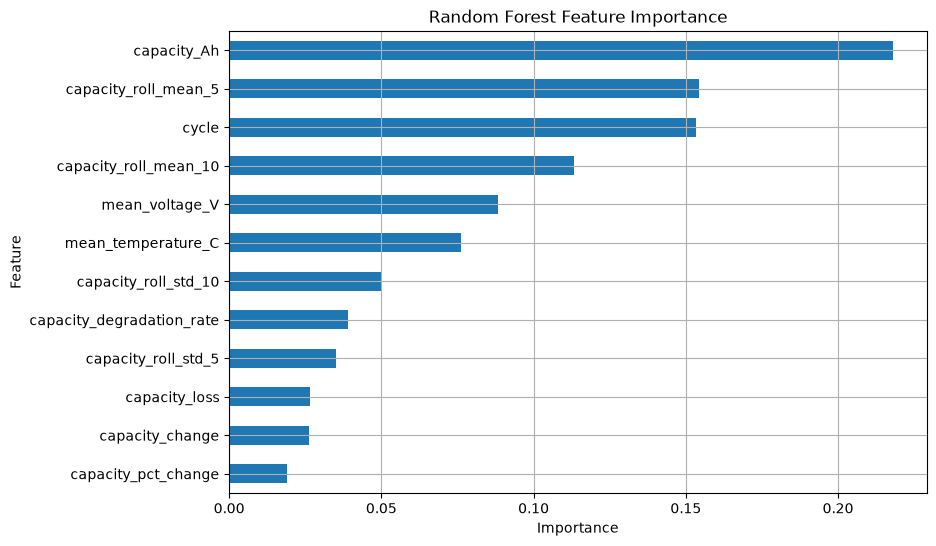

In [40]:
importance = pd.Series(
    rf_improved.feature_importances_,
    index=FEATURES_IMPROVED
).sort_values(ascending=False)

print(importance)

plt.figure(figsize=(9, 6))

importance.sort_values().plot(
    kind="barh"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.grid(True)
plt.show()

In [41]:
test_results["absolute_error"] = (
    test_results["soh"] -
    test_results["predicted_soh"]
).abs()

battery_results = (
    test_results
    .groupby("battery_id")
    .agg(
        MAE=("absolute_error", "mean"),
        Samples=("soh", "count")
    )
    .reset_index()
)

display(
    battery_results.sort_values("MAE")
)

,battery_id,MAE,Samples
0,B0029,0.011367,39
6,B0055,0.018869,101
1,B0030,0.021522,39
4,B0047,0.034391,68
5,B0054,0.040005,101
2,B0038,0.092296,46
3,B0040,0.106406,45


In [42]:
configs = [
    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },
    {
        "n_estimators": 500,
        "max_depth": None,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },
    {
        "n_estimators": 500,
        "max_depth": 15,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },
    {
        "n_estimators": 500,
        "max_depth": 25,
        "min_samples_leaf": 2,
        "max_features": 0.8
    }
]

tuning_results = []

for config in configs:

    model = RandomForestRegressor(
        **config,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    tuning_results.append({
        **config,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.sort_values("RMSE"))

,n_estimators,max_depth,min_samples_leaf,max_features,MAE,RMSE,R2
1,500,NaN,2,sqrt,0.042372,0.082370,0.491794
2,500,15.0,2,sqrt,0.043016,0.082650,0.488340
3,500,25.0,2,0.8,0.046277,0.085944,0.446741
0,300,NaN,1,1.0,0.047753,0.088431,0.414252


In [45]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [46]:
# ============================================
# BLOCK NN-2 — Prepare DNN Data
# ============================================

NN_FEATURES = [
    'cycle',
    'capacity_Ah',

    'max_voltage_V',
    'min_voltage_V',
    'mean_voltage_V',

    'max_current_A',
    'min_current_A',
    'mean_current_A',

    'max_temperature_C',
    'min_temperature_C',
    'mean_temperature_C',

    'discharge_time_s'
]

TARGET = 'soh'

# Create the feature matrix directly from the original dataframe
X_nn = df[NN_FEATURES].copy()
y_nn = df[TARGET].copy()

# Use the EXISTING battery-level split
X_train_nn = X_nn.iloc[train_idx].copy()
X_test_nn  = X_nn.iloc[test_idx].copy()

y_train_nn = y_nn.iloc[train_idx].copy()
y_test_nn  = y_nn.iloc[test_idx].copy()

print("DNN Features:")
print(NN_FEATURES)

print("\nTraining shape:", X_train_nn.shape)
print("Testing shape :", X_test_nn.shape)

print("\nTraining SOH range:")
print(y_train_nn.min(), "to", y_train_nn.max())

print("\nTesting SOH range:")
print(y_test_nn.min(), "to", y_test_nn.max())

DNN Features:
['cycle', 'capacity_Ah', 'max_voltage_V', 'min_voltage_V', 'mean_voltage_V', 'max_current_A', 'min_current_A', 'mean_current_A', 'max_temperature_C', 'min_temperature_C', 'mean_temperature_C', 'discharge_time_s']

Training shape: (2053, 12)
Testing shape : (439, 12)

Training SOH range:
0.3213131633159661 to 1.81597614789334

Testing SOH range:
0.3885031407003622 to 1.1335922074343707


In [47]:
scaler_nn = StandardScaler()

X_train_scaled = scaler_nn.fit_transform(X_train_nn)
X_test_scaled  = scaler_nn.transform(X_test_nn)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape :", X_test_scaled.shape)

Scaled training shape: (2053, 12)
Scaled testing shape : (439, 12)


In [48]:
dnn_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),

    layers.Dense(1, activation='linear')
])

dnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

dnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,105 (27.75 KB)

 Trainable params: 7,105 (27.75 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
history_dnn = dnn_model.fit(
    X_train_scaled,
    y_train_nn,
    validation_split=0.15,
    epochs=200,
    batch_size=32,
    verbose=1,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=20,
            restore_best_weights=True
        )
    ]
)

Epoch 1/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.1014 - mae: 0.2149 - val_loss: 0.0892 - val_mae: 0.2272
Epoch 2/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0131 - mae: 0.0787 - val_loss: 0.0696 - val_mae: 0.1992
Epoch 3/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0042 - mae: 0.0455 - val_loss: 0.0593 - val_mae: 0.1847
Epoch 4/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0021 - mae: 0.0317 - val_loss: 0.0497 - val_mae: 0.1688
Epoch 5/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0013 - mae: 0.0262 - val_loss: 0.0492 - val_mae: 0.1676
Epoch 6/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0011 - mae: 0.0236 - val_loss: 0.0443 - val_mae: 0.1599
Epoch 7/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.7854e-04 - mae: 0.0216 - val_loss: 0.0457 - val_mae: 0.1617
Epoch 8/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.3060e-04 - mae: 0.0197 - val_loss: 0.0418 - val_mae: 0.1545
Epoch 9/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - lo

In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred_dnn = dnn_model.predict(X_test_scaled, verbose=0).flatten()

dnn_mae = mean_absolute_error(y_test_nn, y_pred_dnn)
dnn_rmse = np.sqrt(mean_squared_error(y_test_nn, y_pred_dnn))
dnn_r2 = r2_score(y_test_nn, y_pred_dnn)

print("DNN Results")
print("-" * 30)
print(f"MAE  : {dnn_mae:.6f}")
print(f"RMSE : {dnn_rmse:.6f}")
print(f"R²   : {dnn_r2:.6f}")

DNN Results
------------------------------
MAE  : 0.088332
RMSE : 0.123854
R²   : -0.134295


In [51]:
results.append({
    'Model': 'DNN',
    'MAE': dnn_mae,
    'RMSE': dnn_rmse,
    'R2': dnn_r2
})

results_df = pd.DataFrame(results)

results_df.sort_values('RMSE')

,Model,MAE,RMSE,R2
2,Extra Trees,0.039892,0.058453,0.762362
1,Random Forest,0.049110,0.072764,0.631757
0,Linear Regression,0.062812,0.086198,0.483234
3,Gradient Boosting,0.066610,0.101299,0.286318
4,DNN,0.088332,0.123854,-0.134295


In [52]:
# ============================================
# DNN-1 — Prepare Engineered SOH Dataset
# ============================================

DNN_FEATURES = [
    "cycle",
    "capacity_Ah",
    "mean_voltage_V",
    "mean_temperature_C",
    "capacity_change",
    "capacity_loss",
    "capacity_pct_change",
    "capacity_roll_mean_5",
    "capacity_roll_std_5",
    "capacity_roll_mean_10",
    "capacity_roll_std_10",
    "capacity_degradation_rate"
]

X_dnn = df_feat[DNN_FEATURES].copy()
y_dnn = df_feat["soh"].copy()
groups_dnn = df_feat["battery_id"].copy()

print("Number of features:", len(DNN_FEATURES))
print(DNN_FEATURES)

print("\nDataset shape:", X_dnn.shape)
print("SOH range:", y_dnn.min(), "to", y_dnn.max())

Number of features: 12
['cycle', 'capacity_Ah', 'mean_voltage_V', 'mean_temperature_C', 'capacity_change', 'capacity_loss', 'capacity_pct_change', 'capacity_roll_mean_5', 'capacity_roll_std_5', 'capacity_roll_mean_10', 'capacity_roll_std_10', 'capacity_degradation_rate']

Dataset shape: (2492, 12)
SOH range: 0.3213131633159661 to 1.81597614789334


In [53]:
# ============================================
# DNN-2 — Battery-Level Train/Test Split
# ============================================

gss_dnn = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx_dnn, test_idx_dnn = next(
    gss_dnn.split(
        X_dnn,
        y_dnn,
        groups=groups_dnn
    )
)

X_train_dnn = X_dnn.iloc[train_idx_dnn].copy()
X_test_dnn  = X_dnn.iloc[test_idx_dnn].copy()

y_train_dnn = y_dnn.iloc[train_idx_dnn].copy()
y_test_dnn  = y_dnn.iloc[test_idx_dnn].copy()

train_batteries_dnn = groups_dnn.iloc[train_idx_dnn].unique()
test_batteries_dnn  = groups_dnn.iloc[test_idx_dnn].unique()

print("Training batteries:")
print(train_batteries_dnn)

print("\nTesting batteries:")
print(test_batteries_dnn)

print("\nBattery overlap:",
      set(train_batteries_dnn) & set(test_batteries_dnn))

Training batteries:
<StringArray>
['B0005', 'B0006', 'B0007', 'B0018', 'B0025', 'B0026', 'B0027', 'B0028',
 'B0031', 'B0032', 'B0033', 'B0034', 'B0036', 'B0039', 'B0041', 'B0042',
 'B0043', 'B0044', 'B0045', 'B0046', 'B0048', 'B0049', 'B0051', 'B0053',
 'B0056']
Length: 25, dtype: str

Testing batteries:
<StringArray>
['B0029', 'B0030', 'B0038', 'B0040', 'B0047', 'B0054', 'B0055']
Length: 7, dtype: str

Battery overlap: set()


In [54]:
# ============================================
# DNN-3 — Feature + Target Scaling
# ============================================

from sklearn.preprocessing import StandardScaler

x_scaler_dnn = StandardScaler()
y_scaler_dnn = StandardScaler()

X_train_scaled = x_scaler_dnn.fit_transform(X_train_dnn)
X_test_scaled  = x_scaler_dnn.transform(X_test_dnn)

# Scale target SOH
y_train_scaled = y_scaler_dnn.fit_transform(
    y_train_dnn.to_numpy().reshape(-1, 1)
).ravel()

y_test_scaled = y_scaler_dnn.transform(
    y_test_dnn.to_numpy().reshape(-1, 1)
).ravel()

print("X train:", X_train_scaled.shape)
print("X test :", X_test_scaled.shape)

print("Scaled SOH mean:", y_train_scaled.mean())
print("Scaled SOH std :", y_train_scaled.std())

X train: (2053, 12)
X test : (439, 12)
Scaled SOH mean: -6.2297950529380435e-16
Scaled SOH std : 1.0


In [55]:
# ============================================
# DNN-4 — Deep Neural Network
# ============================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)

dnn_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(32, activation="relu"),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="linear")
])

dnn_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

dnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,129 (31.75 KB)

 Trainable params: 7,873 (30.75 KB)

 Non-trainable params: 256 (1.00 KB)

In [56]:
# ============================================
# DNN-5 — Train
# ============================================

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=10,
    min_lr=1e-6
)

history_dnn = dnn_model.fit(
    X_train_scaled,
    y_train_scaled,

    validation_split=0.15,

    epochs=300,
    batch_size=32,

    callbacks=[
        early_stop,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/300
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.5991 - mae: 0.5874 - val_loss: 1.4320 - val_mae: 0.7985 - learning_rate: 0.0010
Epoch 2/300
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3100 - mae: 0.4093 - val_loss: 1.3702 - val_mae: 0.8213 - learning_rate: 0.0010
Epoch 3/300
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2723 - mae: 0.3836 - val_loss: 1.4706 - val_mae: 0.8292 - learning_rate: 0.0010
Epoch 4/300
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2241 - mae: 0.3413 - val_loss: 1.4207 - val_mae: 0.8534 - learning_rate: 0.0010
Epoch 5/300
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2167 - mae: 0.3369 - val_loss: 1.5672 - val_mae: 0.8971 - learning_rate: 0.0010
Epoch 6/300
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1944 - mae: 0.3145 - val_loss: 1.6355 - val_mae: 0.9022 - learning_rate: 0.0010
Epoch 7/300
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1747 - mae: 0.3018 - val_loss: 1.5438 - val_mae: 0.9241 - learning_rate: 0.0010
Epoch 8/300
5

In [57]:
# ============================================
# DNN-6 — Predictions
# ============================================

y_pred_scaled = dnn_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

# Convert back to original SOH scale
y_pred_dnn = y_scaler_dnn.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

print("Actual SOH range:")
print(y_test_dnn.min(), "to", y_test_dnn.max())

print("\nPredicted SOH range:")
print(y_pred_dnn.min(), "to", y_pred_dnn.max())

Actual SOH range:
0.3213131633159661 to 1.0991572706447514

Predicted SOH range:
0.5672512 to 1.2302463


In [58]:
# ============================================
# DNN-7 — Evaluation
# ============================================

dnn_mae = mean_absolute_error(
    y_test_dnn,
    y_pred_dnn
)

dnn_rmse = np.sqrt(
    mean_squared_error(
        y_test_dnn,
        y_pred_dnn
    )
)

dnn_r2 = r2_score(
    y_test_dnn,
    y_pred_dnn
)

print("\nDNN RESULTS")
print("=" * 40)

print(f"MAE  : {dnn_mae:.6f}")
print(f"RMSE : {dnn_rmse:.6f}")
print(f"R²   : {dnn_r2:.6f}")


DNN RESULTS
MAE  : 0.060708
RMSE : 0.095887
R²   : 0.311309


In [59]:
# ============================================
# DNN-8 — Add DNN to Model Comparison
# ============================================

dnn_result = pd.DataFrame({
    "Model": ["DNN"],
    "MAE": [dnn_mae],
    "RMSE": [dnn_rmse],
    "R2": [dnn_r2]
})

display(dnn_result)

,Model,MAE,RMSE,R2
0,DNN,0.060708,0.095887,0.311309


In [60]:
# ============================================
# BATTERY SELECTION — BLOCK 1
# ============================================

battery_stats = df_feat.groupby("battery_id").agg(
    cycles=("cycle", "count"),
    max_cycle=("cycle", "max"),

    soh_start=("soh", "first"),
    soh_end=("soh", "last"),
    soh_min=("soh", "min"),
    soh_max=("soh", "max"),

    capacity_start=("capacity_Ah", "first"),
    capacity_end=("capacity_Ah", "last"),

    temperature_mean=("mean_temperature_C", "mean"),
    voltage_mean=("mean_voltage_V", "mean")
).reset_index()

battery_stats["soh_drop"] = (
    battery_stats["soh_start"] -
    battery_stats["soh_end"]
)

battery_stats["capacity_drop"] = (
    battery_stats["capacity_start"] -
    battery_stats["capacity_end"]
)

battery_stats["soh_range"] = (
    battery_stats["soh_max"] -
    battery_stats["soh_min"]
)

display(
    battery_stats.sort_values(
        "cycles",
        ascending=False
    )
)

,battery_id,cycles,max_cycle,soh_start,soh_end,soh_min,soh_max,capacity_start,capacity_end,temperature_mean,voltage_mean,soh_drop,capacity_drop,soh_range
13,B0034,196,197,1.071096,0.824920,0.812191,1.172891,1.662322,1.280260,39.217705,3.392737,0.246177,0.382062,0.360701
14,B0036,196,197,1.006690,0.871436,0.871436,1.366061,1.801101,1.559113,30.863449,3.465141,0.135254,0.241988,0.494625
12,B0033,187,197,0.706219,0.800009,0.513336,1.146619,1.161085,1.315283,38.349582,3.366250,-0.093789,-0.154198,0.633283
0,B0005,167,168,1.006051,0.722027,0.701524,1.009035,1.846327,1.325079,32.792630,3.516709,0.284024,0.521248,0.307511
2,B0007,167,168,0.999991,0.761679,0.744664,1.001496,1.880637,1.432455,32.366211,3.517542,0.238312,0.448182,0.256832
1,B0006,167,168,1.028736,0.602302,0.586120,1.028736,2.025140,1.185675,32.796556,3.463145,0.426434,0.839465,0.442616
3,B0018,131,132,1.011602,0.736010,0.736010,1.011602,1.843196,1.341051,31.089008,3.495594,0.275592,0.502144,0.275592
31,B0056,101,102,1.052613,0.884039,0.843138,1.052613,1.344356,1.129059,10.354637,3.351671,0.168574,0.215297,0.209475
29,B0054,101,102,1.085207,0.779005,0.779005,1.085207,1.166544,0.837392,13.597434,3.142126,0.306202,0.329152,0.306202
30,B0055,101,102,1.099157,0.825068,0.817510,1.099157,1.319892,0.990759,11.656881,3.366297,0.274090,0.329133,0.281647


In [61]:
# ============================================
# BATTERY SELECTION — BLOCK 2
# ============================================

print("Battery statistics:")
print()

print("Number of batteries:", len(battery_stats))

print("\nBatteries with SOH > 1.10:")
print(
    battery_stats[
        battery_stats["soh_max"] > 1.10
    ][
        ["battery_id", "soh_max", "soh_min", "cycles"]
    ]
)

print("\nBatteries with SOH < 0.50:")
print(
    battery_stats[
        battery_stats["soh_min"] < 0.50
    ][
        ["battery_id", "soh_max", "soh_min", "cycles"]
    ]
)

Battery statistics:

Number of batteries: 32

Batteries with SOH > 1.10:
   battery_id   soh_max   soh_min  cycles
12      B0033  1.146619  0.513336     187
13      B0034  1.172891  0.812191     196
14      B0036  1.366061  0.871436     196
26      B0049  1.682569  0.489064      23
27      B0051  1.815976  0.528110      23

Batteries with SOH < 0.50:
   battery_id   soh_max   soh_min  cycles
17      B0040  1.000374  0.321313      45
26      B0049  1.682569  0.489064      23


In [62]:
# ============================================
# BATTERY SELECTION — BLOCK 3
# ============================================

battery_stats["degradation_score"] = (
    battery_stats["soh_drop"].abs()
    * np.log1p(battery_stats["cycles"])
)

battery_ranked = battery_stats.sort_values(
    "degradation_score",
    ascending=False
)

display(
    battery_ranked[
        [
            "battery_id",
            "cycles",
            "soh_start",
            "soh_end",
            "soh_drop",
            "capacity_drop",
            "degradation_score"
        ]
    ]
)

,battery_id,cycles,soh_start,soh_end,soh_drop,capacity_drop,degradation_score
1,B0006,167,1.028736,0.602302,0.426434,0.839465,2.185030
26,B0049,23,1.005099,0.489064,0.516035,0.729517,1.639986
22,B0045,69,1.091225,0.713740,0.377486,0.321005,1.603745
27,B0051,23,1.007513,0.528110,0.479403,0.615332,1.523568
0,B0005,167,1.006051,0.722027,0.284024,0.521248,1.455331
29,B0054,101,1.085207,0.779005,0.306202,0.329152,1.416177
3,B0018,131,1.011602,0.736010,0.275592,0.502144,1.345661
13,B0034,196,1.071096,0.824920,0.246177,0.382062,1.300601
30,B0055,101,1.099157,0.825068,0.274090,0.329133,1.267658
2,B0007,167,0.999991,0.761679,0.238312,0.448182,1.221101


In [63]:
# ============================================
# BATTERY ANALYSIS — BLOCK 4
# ============================================

df_check = df.copy()

df_check["capacity_ratio"] = (
    df_check["capacity_Ah"] /
    df_check["rated_capacity_Ah"]
)

battery_quality = df_check.groupby("battery_id").agg(
    cycles=("cycle", "count"),

    soh_min=("soh", "min"),
    soh_max=("soh", "max"),

    capacity_min=("capacity_Ah", "min"),
    capacity_max=("capacity_Ah", "max"),

    rated_capacity=("rated_capacity_Ah", "first"),

    ratio_min=("capacity_ratio", "min"),
    ratio_max=("capacity_ratio", "max"),
    ratio_mean=("capacity_ratio", "mean")
).reset_index()

display(
    battery_quality.sort_values(
        "soh_max",
        ascending=False
    )
)

,battery_id,cycles,soh_min,soh_max,capacity_min,capacity_max,rated_capacity,ratio_min,ratio_max,ratio_mean
27,B0051,24,0.501328,1.815976,0.643474,2.330873,1.283537,0.501328,1.815976,0.716884
26,B0049,24,0.489064,1.682569,0.691389,2.378644,1.413698,0.489064,1.682569,0.679182
14,B0036,197,0.560039,1.366061,1.001983,2.444062,1.789131,0.560039,1.366061,0.949881
22,B0045,70,0.713740,1.272353,0.606948,1.081979,0.850376,0.713740,1.272353,0.833240
13,B0034,197,0.480631,1.172891,0.745930,1.820306,1.551982,0.480631,1.172891,0.893128
23,B0046,69,0.759623,1.168280,1.123711,1.728239,1.479302,0.759623,1.168280,0.867081
12,B0033,188,0.419425,1.146619,0.689570,1.885140,1.644086,0.419425,1.146619,0.890051
24,B0047,69,0.748805,1.133592,1.105977,1.674305,1.476990,0.748805,1.133592,0.850307
18,B0041,25,0.776599,1.128604,0.836495,1.215649,1.077126,0.776599,1.128604,0.884662
25,B0048,69,0.786620,1.126572,1.157683,1.657996,1.471718,0.786620,1.126572,0.882994


In [64]:
# ============================================
# BATTERY ANALYSIS — BLOCK 5
# ============================================

SUSPICIOUS = [
    "B0049",
    "B0051",
    "B0040",
    "B0038",
    "B0033",
    "B0034",
    "B0036"
]

for battery in SUSPICIOUS:

    temp = df_check[
        df_check["battery_id"] == battery
    ].sort_values("cycle")

    print("\n" + "=" * 60)
    print(battery)

    print(
        temp[
            [
                "cycle",
                "capacity_Ah",
                "rated_capacity_Ah",
                "soh",
                "capacity_ratio"
            ]
        ].head(10)
    )

    print("\nLast cycles:")
    print(
        temp[
            [
                "cycle",
                "capacity_Ah",
                "rated_capacity_Ah",
                "soh",
                "capacity_ratio"
            ]
        ].tail(5)
    )


B0049
      cycle  capacity_Ah  rated_capacity_Ah       soh  capacity_ratio
2115      1     0.858373           1.413698  0.607183        0.607183
2116      2     1.420906           1.413698  1.005099        1.005099
2117      3     1.372852           1.413698  0.971107        0.971107
2118      4     1.364374           1.413698  0.965110        0.965110
2119      5     2.378644           1.413698  1.682569        1.682569
2120      6     1.060536           1.413698  0.750186        0.750186
2121      7     1.006993           1.413698  0.712312        0.712312
2122      8     0.929878           1.413698  0.657763        0.657763
2123      9     0.923238           1.413698  0.653066        0.653066
2124     10     0.905328           1.413698  0.640397        0.640397

Last cycles:
      cycle  capacity_Ah  rated_capacity_Ah       soh  capacity_ratio
2134     21     0.734939           1.413698  0.519870        0.519870
2135     22     0.736676           1.413698  0.521099        0.521099

In [65]:
# ============================================
# BLOCK 6 — SOH Trajectory Quality
# ============================================

df_quality = df_feat.copy()

df_quality = df_quality.sort_values(
    ["battery_id", "cycle"]
)

# Cycle-to-cycle SOH change
df_quality["soh_change"] = (
    df_quality
    .groupby("battery_id")["soh"]
    .diff()
)

# Absolute change
df_quality["abs_soh_change"] = (
    df_quality["soh_change"].abs()
)

battery_quality = df_quality.groupby("battery_id").agg(
    cycles=("cycle", "count"),

    soh_start=("soh", "first"),
    soh_end=("soh", "last"),

    soh_min=("soh", "min"),
    soh_max=("soh", "max"),

    mean_abs_change=("abs_soh_change", "mean"),
    max_abs_change=("abs_soh_change", "max"),

    std_change=("soh_change", "std")
).reset_index()

battery_quality["soh_drop"] = (
    battery_quality["soh_start"]
    - battery_quality["soh_end"]
)

display(
    battery_quality.sort_values(
        "mean_abs_change"
    )
)

,battery_id,cycles,soh_start,soh_end,soh_min,soh_max,mean_abs_change,max_abs_change,std_change,soh_drop
2,B0007,167,0.999991,0.761679,0.744664,1.001496,0.003680,0.052200,0.006468,0.238312
7,B0028,27,1.001427,0.952848,0.952848,1.001427,0.004117,0.015983,0.005635,0.048579
0,B0005,167,1.006051,0.722027,0.701524,1.009035,0.004430,0.048132,0.007064,0.284024
4,B0025,27,1.000275,0.956567,0.956567,1.000502,0.004807,0.012075,0.005775,0.043709
6,B0027,27,0.997054,0.972793,0.972793,1.000129,0.005252,0.017849,0.006979,0.024261
20,B0043,64,1.023944,0.771041,0.771041,1.023944,0.005987,0.033583,0.006580,0.252904
8,B0029,39,1.015673,0.887594,0.887594,1.015673,0.006014,0.022297,0.006446,0.128079
19,B0042,64,1.014836,0.783907,0.783907,1.014836,0.006118,0.074940,0.012104,0.230929
21,B0044,64,1.025340,0.770103,0.770103,1.025340,0.006193,0.038844,0.006913,0.255237
10,B0031,39,1.010405,0.919136,0.919136,1.010405,0.006844,0.023728,0.008415,0.091268


In [66]:
# ============================================
# BLOCK 7 — Abnormal SOH Jumps
# ============================================

JUMP_THRESHOLD = 0.10

jump_stats = (
    df_quality
    .groupby("battery_id")["abs_soh_change"]
    .agg(
        abnormal_jumps=lambda x: (x > JUMP_THRESHOLD).sum(),
        total_changes="count"
    )
    .reset_index()
)

jump_stats["jump_percentage"] = (
    jump_stats["abnormal_jumps"]
    / jump_stats["total_changes"]
    * 100
)

battery_quality = battery_quality.merge(
    jump_stats,
    on="battery_id"
)

display(
    battery_quality.sort_values(
        "jump_percentage"
    )
)

,battery_id,cycles,soh_start,soh_end,soh_min,soh_max,mean_abs_change,max_abs_change,std_change,soh_drop,abnormal_jumps,total_changes,jump_percentage
0,B0005,167,1.006051,0.722027,0.701524,1.009035,0.004430,0.048132,0.007064,0.284024,0,166,0.000000
1,B0006,167,1.028736,0.602302,0.586120,1.028736,0.007306,0.077169,0.011769,0.426434,0,166,0.000000
2,B0007,167,0.999991,0.761679,0.744664,1.001496,0.003680,0.052200,0.006468,0.238312,0,166,0.000000
3,B0018,131,1.011602,0.736010,0.736010,1.011602,0.007778,0.072030,0.012307,0.275592,0,130,0.000000
4,B0025,27,1.000275,0.956567,0.956567,1.000502,0.004807,0.012075,0.005775,0.043709,0,26,0.000000
6,B0027,27,0.997054,0.972793,0.972793,1.000129,0.005252,0.017849,0.006979,0.024261,0,26,0.000000
7,B0028,27,1.001427,0.952848,0.952848,1.001427,0.004117,0.015983,0.005635,0.048579,0,26,0.000000
8,B0029,39,1.015673,0.887594,0.887594,1.015673,0.006014,0.022297,0.006446,0.128079,0,38,0.000000
10,B0031,39,1.010405,0.919136,0.919136,1.010405,0.006844,0.023728,0.008415,0.091268,0,38,0.000000
9,B0030,39,1.016715,0.891863,0.891863,1.016715,0.007533,0.029371,0.008615,0.124852,0,38,0.000000


In [67]:
# ============================================
# BLOCK 8 — Battery Quality Score
# ============================================

battery_quality["quality_score"] = (
    battery_quality["cycles"]
    / (1 + battery_quality["mean_abs_change"])
    / (1 + battery_quality["abnormal_jumps"])
)

battery_quality_ranked = battery_quality.sort_values(
    "quality_score",
    ascending=False
)

display(
    battery_quality_ranked[
        [
            "battery_id",
            "cycles",
            "soh_start",
            "soh_end",
            "soh_drop",
            "mean_abs_change",
            "max_abs_change",
            "abnormal_jumps",
            "jump_percentage",
            "quality_score"
        ]
    ]
)

,battery_id,cycles,soh_start,soh_end,soh_drop,mean_abs_change,max_abs_change,abnormal_jumps,jump_percentage,quality_score
2,B0007,167,0.999991,0.761679,0.238312,0.003680,0.052200,0,0.000000,166.387770
0,B0005,167,1.006051,0.722027,0.284024,0.004430,0.048132,0,0.000000,166.263383
1,B0006,167,1.028736,0.602302,0.426434,0.007306,0.077169,0,0.000000,165.788745
3,B0018,131,1.011602,0.736010,0.275592,0.007778,0.072030,0,0.000000,129.988891
22,B0045,69,1.091225,0.713740,0.377486,0.014195,0.054976,0,0.000000,68.034254
25,B0048,68,1.024445,0.831088,0.193356,0.010760,0.069085,0,0.000000,67.276076
24,B0047,68,1.032076,0.783153,0.248923,0.011077,0.057423,0,0.000000,67.255046
23,B0046,68,1.024908,0.779965,0.244943,0.011164,0.079664,0,0.000000,67.249234
20,B0043,64,1.023944,0.771041,0.252904,0.005987,0.033583,0,0.000000,63.619132
19,B0042,64,1.014836,0.783907,0.230929,0.006118,0.074940,0,0.000000,63.610824


In [68]:
# ============================================
# BLOCK 9 — Select Clean Battery Candidates
# ============================================

MIN_CYCLES = 50
MAX_JUMP_PERCENTAGE = 2.0

clean_candidates = battery_quality[
    (battery_quality["cycles"] >= MIN_CYCLES) &
    (battery_quality["jump_percentage"] <= MAX_JUMP_PERCENTAGE)
].copy()

clean_candidates = clean_candidates.sort_values(
    "quality_score",
    ascending=False
)

print("Clean candidate batteries:")
print(
    clean_candidates[
        [
            "battery_id",
            "cycles",
            "soh_start",
            "soh_end",
            "soh_drop",
            "mean_abs_change",
            "abnormal_jumps",
            "jump_percentage",
            "quality_score"
        ]
    ].to_string(index=False)
)

print("\nNumber of candidates:",
      len(clean_candidates))

Clean candidate batteries:
battery_id  cycles  soh_start  soh_end  soh_drop  mean_abs_change  abnormal_jumps  jump_percentage  quality_score
     B0007     167   0.999991 0.761679  0.238312         0.003680               0         0.000000     166.387770
     B0005     167   1.006051 0.722027  0.284024         0.004430               0         0.000000     166.263383
     B0006     167   1.028736 0.602302  0.426434         0.007306               0         0.000000     165.788745
     B0018     131   1.011602 0.736010  0.275592         0.007778               0         0.000000     129.988891
     B0045      69   1.091225 0.713740  0.377486         0.014195               0         0.000000      68.034254
     B0048      68   1.024445 0.831088  0.193356         0.010760               0         0.000000      67.276076
     B0047      68   1.032076 0.783153  0.248923         0.011077               0         0.000000      67.255046
     B0046      68   1.024908 0.779965  0.244943         0.01

In [69]:
top_10 = clean_candidates.head(10)

In [70]:
# ============================================
# BLOCK 10 — Degradation Categories
# ============================================

clean_candidates["degradation_rate"] = (
    clean_candidates["soh_drop"]
    / clean_candidates["cycles"]
)

clean_candidates["degradation_group"] = pd.qcut(
    clean_candidates["degradation_rate"],
    q=3,
    labels=[
        "Slow",
        "Medium",
        "Fast"
    ],
    duplicates="drop"
)

display(
    clean_candidates[
        [
            "battery_id",
            "cycles",
            "soh_drop",
            "degradation_rate",
            "degradation_group"
        ]
    ].sort_values(
        "degradation_rate"
    )
)

,battery_id,cycles,soh_drop,degradation_rate,degradation_group
2,B0007,167,0.238312,0.001427,Slow
31,B0056,101,0.168574,0.001669,Slow
0,B0005,167,0.284024,0.001701,Slow
3,B0018,131,0.275592,0.002104,Slow
28,B0053,54,0.127886,0.002368,Slow
1,B0006,167,0.426434,0.002553,Medium
30,B0055,101,0.274090,0.002714,Medium
25,B0048,68,0.193356,0.002843,Medium
29,B0054,101,0.306202,0.003032,Medium
23,B0046,68,0.244943,0.003602,Medium


In [71]:
# ============================================
# BLOCK 11 — Representative Training Batteries
# ============================================

representative_train = (
    clean_candidates
    .groupby("degradation_group", observed=True)
    .apply(
        lambda x: x.nlargest(
            4,
            "quality_score"
        ),
        include_groups=False
    )
    .reset_index(drop=True)
)

TRAIN_BATTERIES_SELECTED = (
    representative_train["battery_id"]
    .tolist()
)

print("Selected training batteries:")
print(TRAIN_BATTERIES_SELECTED)

print("\nTotal:",
      len(TRAIN_BATTERIES_SELECTED))

Selected training batteries:
['B0007', 'B0005', 'B0018', 'B0056', 'B0006', 'B0048', 'B0046', 'B0055', 'B0045', 'B0047', 'B0043', 'B0042']

Total: 12


In [72]:
# ============================================
# BLOCK 11 — Representative Training Batteries
# ============================================

representative_train = (
    clean_candidates
    .groupby("degradation_group", observed=True)
    .apply(
        lambda x: x.nlargest(
            4,
            "quality_score"
        ),
        include_groups=False
    )
    .reset_index(drop=True)
)

TRAIN_BATTERIES_SELECTED = (
    representative_train["battery_id"]
    .tolist()
)

print("Selected training batteries:")
print(TRAIN_BATTERIES_SELECTED)

print("\nTotal:",
      len(TRAIN_BATTERIES_SELECTED))

Selected training batteries:
['B0007', 'B0005', 'B0018', 'B0056', 'B0006', 'B0048', 'B0046', 'B0055', 'B0045', 'B0047', 'B0043', 'B0042']

Total: 12


In [74]:
# ============================================
# BLOCK 12 — Unseen Test Batteries
# ============================================

remaining_clean = clean_candidates[
    ~clean_candidates["battery_id"].isin(
        TRAIN_BATTERIES_SELECTED
    )
].copy()

# Select a diverse set of remaining batteries
TEST_BATTERIES_SELECTED = (
    remaining_clean
    .groupby("degradation_group", observed=True)
    .apply(
        lambda x: x.nlargest(
            2,
            "cycles"
        ),
        include_groups=False
    )
    .reset_index(drop=True)["battery_id"]
    .tolist()
)

print("Unseen test batteries:")
print(TEST_BATTERIES_SELECTED)

print("\nOverlap:")
print(
    set(TRAIN_BATTERIES_SELECTED)
    &
    set(TEST_BATTERIES_SELECTED)
)

Unseen test batteries:
['B0053', 'B0054', 'B0044']

Overlap:
set()


In [75]:
# ============================================
# BLOCK 13 — Build Selected Dataset
# ============================================

selected_batteries = (
    TRAIN_BATTERIES_SELECTED +
    TEST_BATTERIES_SELECTED
)

df_selected = df_feat[
    df_feat["battery_id"].isin(
        selected_batteries
    )
].copy()

print("Selected dataset shape:")
print(df_selected.shape)

print("\nTraining batteries:")
print(TRAIN_BATTERIES_SELECTED)

print("\nTesting batteries:")
print(TEST_BATTERIES_SELECTED)

Selected dataset shape:
(1454, 25)

Training batteries:
['B0007', 'B0005', 'B0018', 'B0056', 'B0006', 'B0048', 'B0046', 'B0055', 'B0045', 'B0047', 'B0043', 'B0042']

Testing batteries:
['B0053', 'B0054', 'B0044']


In [76]:
# ============================================
# BLOCK 14 — Prepare DNN Data
# ============================================

DNN_FEATURES = [
    "cycle",
    "capacity_Ah",
    "mean_voltage_V",
    "mean_temperature_C",
    "capacity_change",
    "capacity_loss",
    "capacity_pct_change",
    "capacity_roll_mean_5",
    "capacity_roll_std_5",
    "capacity_roll_mean_10",
    "capacity_roll_std_10",
    "capacity_degradation_rate"
]

train_df_selected = df_selected[
    df_selected["battery_id"].isin(
        TRAIN_BATTERIES_SELECTED
    )
].copy()

test_df_selected = df_selected[
    df_selected["battery_id"].isin(
        TEST_BATTERIES_SELECTED
    )
].copy()

X_train_sel = train_df_selected[DNN_FEATURES]
X_test_sel  = test_df_selected[DNN_FEATURES]

y_train_sel = train_df_selected["soh"]
y_test_sel  = test_df_selected["soh"]

print("Train shape:", X_train_sel.shape)
print("Test shape :", X_test_sel.shape)

Train shape: (1235, 12)
Test shape : (219, 12)


In [77]:
# ============================================
# BLOCK 15 — Scale Selected Dataset
# ============================================

from sklearn.preprocessing import StandardScaler

x_scaler_sel = StandardScaler()
y_scaler_sel = StandardScaler()

X_train_sel_scaled = x_scaler_sel.fit_transform(
    X_train_sel
)

X_test_sel_scaled = x_scaler_sel.transform(
    X_test_sel
)

y_train_sel_scaled = y_scaler_sel.fit_transform(
    y_train_sel.to_numpy().reshape(-1, 1)
).ravel()

y_test_sel_scaled = y_scaler_sel.transform(
    y_test_sel.to_numpy().reshape(-1, 1)
).ravel()

In [78]:
# ============================================
# BLOCK 16 — Selected-Battery DNN
# ============================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)

model_sel = keras.Sequential([
    layers.Input(
        shape=(X_train_sel_scaled.shape[1],)
    ),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(32, activation="relu"),

    layers.Dense(16, activation="relu"),

    layers.Dense(1)
])

model_sel.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

model_sel.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,129 (31.75 KB)

 Trainable params: 7,873 (30.75 KB)

 Non-trainable params: 256 (1.00 KB)

In [79]:
# ============================================
# BLOCK 17 — Train Selected-Battery DNN
# ============================================

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=10,
    min_lr=1e-6
)

history_sel = model_sel.fit(
    X_train_sel_scaled,
    y_train_sel_scaled,

    validation_split=0.15,

    epochs=300,
    batch_size=32,

    callbacks=[
        early_stop,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/300
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.8470 - mae: 0.6998 - val_loss: 0.4331 - val_mae: 0.5316 - learning_rate: 0.0010
Epoch 2/300
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3195 - mae: 0.4392 - val_loss: 0.4031 - val_mae: 0.5258 - learning_rate: 0.0010
Epoch 3/300
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2680 - mae: 0.3949 - val_loss: 0.4259 - val_mae: 0.5578 - learning_rate: 0.0010
Epoch 4/300
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2079 - mae: 0.3572 - val_loss: 0.4944 - val_mae: 0.6307 - learning_rate: 0.0010
Epoch 5/300
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1990 - mae: 0.3485 - val_loss: 0.5517 - val_mae: 0.6795 - learning_rate: 0.0010
Epoch 6/300
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1723 - mae: 0.3212 - val_loss: 0.5980 - val_mae: 0.7160 - learning_rate: 0.0010
Epoch 7/300
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1563 - mae: 0.3058 - val_loss: 0.8344 - val_mae: 0.8571 - learning_rate: 0.0010
Epoch 8/300


In [80]:
# ============================================
# BLOCK 18 — Evaluate
# ============================================

y_pred_sel_scaled = model_sel.predict(
    X_test_sel_scaled,
    verbose=0
).ravel()

y_pred_sel = y_scaler_sel.inverse_transform(
    y_pred_sel_scaled.reshape(-1, 1)
).ravel()

sel_mae = mean_absolute_error(
    y_test_sel,
    y_pred_sel
)

sel_rmse = np.sqrt(
    mean_squared_error(
        y_test_sel,
        y_pred_sel
    )
)

sel_r2 = r2_score(
    y_test_sel,
    y_pred_sel
)

print("SELECTED-BATTERY DNN")
print("=" * 40)

print(f"MAE  : {sel_mae:.6f}")
print(f"RMSE : {sel_rmse:.6f}")
print(f"R²   : {sel_r2:.6f}")

SELECTED-BATTERY DNN
MAE  : 0.055724
RMSE : 0.066902
R²   : -0.145903


In [81]:
# ============================================
# BLOCK 19 — FIXED TEST BATTERIES
# ============================================

FIXED_TEST_BATTERIES = [
    "B0029",
    "B0030",
    "B0038",
    "B0040",
    "B0047",
    "B0054"
]

# Anomalous batteries identified from our
# trajectory-quality analysis
ANOMALOUS_BATTERIES = [
    "B0026",
    "B0033",
    "B0034",
    "B0036",
    "B0039",
    "B0049",
    "B0051",
    "B0053"
]

# Fixed test set
test_fixed = df_feat[
    df_feat["battery_id"].isin(
        FIXED_TEST_BATTERIES
    )
].copy()

# All other batteries
train_all = df_feat[
    ~df_feat["battery_id"].isin(
        FIXED_TEST_BATTERIES
    )
].copy()

# Remove anomalous batteries from training
train_clean = train_all[
    ~train_all["battery_id"].isin(
        ANOMALOUS_BATTERIES
    )
].copy()

print("FIXED TEST:")
print(
    sorted(
        test_fixed["battery_id"].unique()
    )
)

print("\nALL TRAIN:")
print(
    len(train_all),
    "rows"
)

print("\nCLEAN TRAIN:")
print(
    len(train_clean),
    "rows"
)

print("\nClean training batteries:")
print(
    sorted(
        train_clean["battery_id"].unique()
    )
)

FIXED TEST:
['B0029', 'B0030', 'B0038', 'B0040', 'B0047', 'B0054']

ALL TRAIN:
2154 rows

CLEAN TRAIN:
1414 rows

Clean training batteries:
['B0005', 'B0006', 'B0007', 'B0018', 'B0025', 'B0027', 'B0028', 'B0031', 'B0032', 'B0041', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0048', 'B0055', 'B0056']


In [82]:
# ============================================
# BLOCK 20 — Clean Training Dataset
# ============================================

DNN_FEATURES = [
    "cycle",
    "capacity_Ah",
    "mean_voltage_V",
    "mean_temperature_C",
    "capacity_change",
    "capacity_loss",
    "capacity_pct_change",
    "capacity_roll_mean_5",
    "capacity_roll_std_5",
    "capacity_roll_mean_10",
    "capacity_roll_std_10",
    "capacity_degradation_rate"
]

X_train_clean = train_clean[
    DNN_FEATURES
].copy()

y_train_clean = train_clean[
    "soh"
].copy()

X_test_fixed = test_fixed[
    DNN_FEATURES
].copy()

y_test_fixed = test_fixed[
    "soh"
].copy()

print("Train:", X_train_clean.shape)
print("Test :", X_test_fixed.shape)

Train: (1414, 12)
Test : (338, 12)


In [83]:
# ============================================
# BLOCK 21 — Scaling
# ============================================

from sklearn.preprocessing import StandardScaler

x_scaler_clean = StandardScaler()
y_scaler_clean = StandardScaler()

X_train_clean_scaled = (
    x_scaler_clean.fit_transform(
        X_train_clean
    )
)

X_test_fixed_scaled = (
    x_scaler_clean.transform(
        X_test_fixed
    )
)

y_train_clean_scaled = (
    y_scaler_clean.fit_transform(
        y_train_clean.to_numpy().reshape(-1, 1)
    ).ravel()
)

In [84]:
# ============================================
# BLOCK 22 — Clean-Battery DNN
# ============================================

tf.random.set_seed(42)
np.random.seed(42)

model_clean = keras.Sequential([
    layers.Input(
        shape=(X_train_clean_scaled.shape[1],)
    ),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(32, activation="relu"),

    layers.Dense(16, activation="relu"),

    layers.Dense(1)
])

model_clean.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

history_clean = model_clean.fit(
    X_train_clean_scaled,
    y_train_clean_scaled,

    validation_split=0.15,

    epochs=300,
    batch_size=32,

    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=30,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=10,
            min_lr=1e-6
        )
    ],

    verbose=1
)

Epoch 1/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 11s 135ms/step - loss: 0.6172 - mae: 0.5983 - val_loss: 0.2598 - val_mae: 0.4003 - learning_rate: 0.0010
Epoch 2/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2596 - mae: 0.3952 - val_loss: 0.2611 - val_mae: 0.4103 - learning_rate: 0.0010
Epoch 3/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2158 - mae: 0.3566 - val_loss: 0.2588 - val_mae: 0.4162 - learning_rate: 0.0010
Epoch 4/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1648 - mae: 0.3128 - val_loss: 0.3052 - val_mae: 0.4473 - learning_rate: 0.0010
Epoch 5/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1461 - mae: 0.2949 - val_loss: 0.3946 - val_mae: 0.5238 - learning_rate: 0.0010
Epoch 6/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1369 - mae: 0.2820 - val_loss: 0.4370 - val_mae: 0.5606 - learning_rate: 0.0010
Epoch 7/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1265 - mae: 0.2696 - val_loss: 0.4822 - val_mae: 0.6023 - learning_rate: 0.0010
Epoch 8/30

In [85]:
# ============================================
# BLOCK 23 — Fixed Test Evaluation
# ============================================

pred_scaled = model_clean.predict(
    X_test_fixed_scaled,
    verbose=0
).ravel()

pred_clean = y_scaler_clean.inverse_transform(
    pred_scaled.reshape(-1, 1)
).ravel()

clean_mae = mean_absolute_error(
    y_test_fixed,
    pred_clean
)

clean_rmse = np.sqrt(
    mean_squared_error(
        y_test_fixed,
        pred_clean
    )
)

clean_r2 = r2_score(
    y_test_fixed,
    pred_clean
)

print("CLEAN TRAINING / FIXED TEST")
print("=" * 45)

print(f"MAE  : {clean_mae:.6f}")
print(f"RMSE : {clean_rmse:.6f}")
print(f"R²   : {clean_r2:.6f}")

CLEAN TRAINING / FIXED TEST
MAE  : 0.071583
RMSE : 0.115810
R²   : 0.185119


In [86]:
TEST_BATTERIES = [
    "B0029",
    "B0030",
    "B0038",
    "B0040",
    "B0047",
    "B0054"
]

In [87]:
FEATURES_A = [
    "cycle",
    "capacity_Ah",
    "rated_capacity_Ah"
]

In [88]:
FEATURES_B = [
    "cycle",
    "max_voltage_V",
    "min_voltage_V",
    "mean_voltage_V",
    "max_current_A",
    "min_current_A",
    "mean_current_A",
    "max_temperature_C",
    "min_temperature_C",
    "mean_temperature_C",
    "discharge_time_s",
    "rated_capacity_Ah"
]

In [89]:
# ============================================
# FEATURE SET B — ELECTRICAL + THERMAL DNN
# ============================================

TEST_BATTERIES = [
    "B0029",
    "B0030",
    "B0038",
    "B0040",
    "B0047",
    "B0054"
]

train_B = df_feat[
    ~df_feat["battery_id"].isin(TEST_BATTERIES)
].copy()

test_B = df_feat[
    df_feat["battery_id"].isin(TEST_BATTERIES)
].copy()

print("Training shape:", train_B.shape)
print("Testing shape :", test_B.shape)

print("\nTraining batteries:")
print(sorted(train_B["battery_id"].unique()))

print("\nTesting batteries:")
print(sorted(test_B["battery_id"].unique()))

Training shape: (2154, 25)
Testing shape : (338, 25)

Training batteries:
['B0005', 'B0006', 'B0007', 'B0018', 'B0025', 'B0026', 'B0027', 'B0028', 'B0031', 'B0032', 'B0033', 'B0034', 'B0036', 'B0039', 'B0041', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0048', 'B0049', 'B0051', 'B0053', 'B0055', 'B0056']

Testing batteries:
['B0029', 'B0030', 'B0038', 'B0040', 'B0047', 'B0054']


In [90]:
FEATURES_B = [
    "cycle",
    "max_voltage_V",
    "min_voltage_V",
    "mean_voltage_V",
    "max_current_A",
    "min_current_A",
    "mean_current_A",
    "max_temperature_C",
    "min_temperature_C",
    "mean_temperature_C",
    "discharge_time_s",
    "rated_capacity_Ah"
]

In [91]:
X_train_B = train_B[FEATURES_B].copy()
X_test_B  = test_B[FEATURES_B].copy()

y_train_B = train_B["soh"].copy()
y_test_B  = test_B["soh"].copy()

print("X_train:", X_train_B.shape)
print("X_test :", X_test_B.shape)

print("y_train:", y_train_B.shape)
print("y_test :", y_test_B.shape)

X_train: (2154, 12)
X_test : (338, 12)
y_train: (2154,)
y_test : (338,)


In [92]:
print("NaN in training:")
print(X_train_B.isna().sum())

print("\nNaN in testing:")
print(X_test_B.isna().sum())

print("\nInfinite values:")
print(np.isinf(X_train_B.select_dtypes(include=np.number)).sum().sum())

NaN in training:
cycle                 0
max_voltage_V         0
min_voltage_V         0
mean_voltage_V        0
max_current_A         0
min_current_A         0
mean_current_A        0
max_temperature_C     0
min_temperature_C     0
mean_temperature_C    0
discharge_time_s      0
rated_capacity_Ah     0
dtype: int64

NaN in testing:
cycle                 0
max_voltage_V         0
min_voltage_V         0
mean_voltage_V        0
max_current_A         0
min_current_A         0
mean_current_A        0
max_temperature_C     0
min_temperature_C     0
mean_temperature_C    0
discharge_time_s      0
rated_capacity_Ah     0
dtype: int64

Infinite values:
0


In [93]:
from sklearn.preprocessing import StandardScaler

X_scaler_B = StandardScaler()
y_scaler_B = StandardScaler()

X_train_B_scaled = X_scaler_B.fit_transform(X_train_B)
X_test_B_scaled  = X_scaler_B.transform(X_test_B)

y_train_B_scaled = y_scaler_B.fit_transform(
    y_train_B.to_numpy().reshape(-1, 1)
).ravel()

print("Scaling completed.")

Scaling completed.


In [94]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)

model_B = keras.Sequential([
    layers.Input(
        shape=(X_train_B_scaled.shape[1],)
    ),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(32, activation="relu"),

    layers.Dense(16, activation="relu"),

    layers.Dense(1)
])

model_B.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

model_B.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,129 (31.75 KB)

 Trainable params: 7,873 (30.75 KB)

 Non-trainable params: 256 (1.00 KB)

In [95]:
callbacks_B = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=30,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=10,
        min_lr=1e-6
    )
]

history_B = model_B.fit(
    X_train_B_scaled,
    y_train_B_scaled,

    validation_split=0.15,

    epochs=300,
    batch_size=32,

    callbacks=callbacks_B,

    verbose=1
)


Epoch 1/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 61s 40ms/step - loss: 0.6958 - mae: 0.6212 - val_loss: 1.6591 - val_mae: 0.7651 - learning_rate: 0.0010
Epoch 2/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2907 - mae: 0.4099 - val_loss: 1.5772 - val_mae: 0.7639 - learning_rate: 0.0010
Epoch 3/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2371 - mae: 0.3659 - val_loss: 1.5029 - val_mae: 0.7635 - learning_rate: 0.0010
Epoch 4/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2153 - mae: 0.3428 - val_loss: 1.4103 - val_mae: 0.7577 - learning_rate: 0.0010
Epoch 5/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1891 - mae: 0.3246 - val_loss: 1.3302 - val_mae: 0.8011 - learning_rate: 0.0010
Epoch 6/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1833 - mae: 0.3169 - val_loss: 1.2929 - val_mae: 0.8439 - learning_rate: 0.0010
Epoch 7/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1622 - mae: 0.3049 - val_loss: 1.3917 - val_mae: 0.9159 - learning_rate: 0.0010
Epoch 8/300

In [96]:
pred_B_scaled = model_B.predict(
    X_test_B_scaled,
    verbose=0
).ravel()

pred_B = y_scaler_B.inverse_transform(
    pred_B_scaled.reshape(-1, 1)
).ravel()

print("Prediction completed.")

Prediction completed.


In [97]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae_B = mean_absolute_error(
    y_test_B,
    pred_B
)

rmse_B = np.sqrt(
    mean_squared_error(
        y_test_B,
        pred_B
    )
)

r2_B = r2_score(
    y_test_B,
    pred_B
)

print("\n======================================")
print("FEATURE SET B — ELECTRICAL + THERMAL")
print("======================================")

print(f"MAE  : {mae_B:.6f}")
print(f"RMSE : {rmse_B:.6f}")
print(f"R²   : {r2_B:.6f}")


FEATURE SET B — ELECTRICAL + THERMAL
MAE  : 0.077236
RMSE : 0.119010
R²   : 0.139475


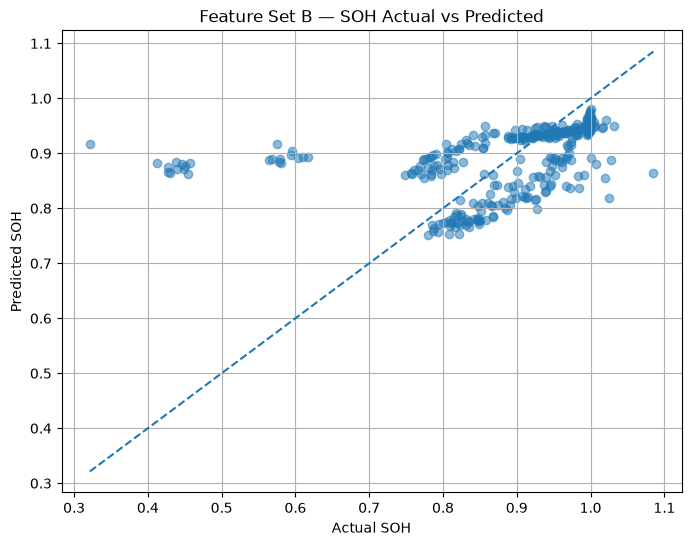

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_B,
    pred_B,
    alpha=0.5
)

minimum = min(
    y_test_B.min(),
    pred_B.min()
)

maximum = max(
    y_test_B.max(),
    pred_B.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "--"
)

plt.xlabel("Actual SOH")
plt.ylabel("Predicted SOH")
plt.title("Feature Set B — SOH Actual vs Predicted")
plt.grid(True)

plt.show()

In [99]:
results_B = test_B[
    ["battery_id", "cycle", "soh"]
].copy()

results_B["predicted_soh"] = pred_B

battery_results_B = []

for battery_id, group in results_B.groupby("battery_id"):

    mae = mean_absolute_error(
        group["soh"],
        group["predicted_soh"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            group["soh"],
            group["predicted_soh"]
        )
    )

    r2 = r2_score(
        group["soh"],
        group["predicted_soh"]
    )

    battery_results_B.append({
        "battery_id": battery_id,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "samples": len(group)
    })

battery_results_B = pd.DataFrame(
    battery_results_B
)

battery_results_B

,battery_id,MAE,RMSE,R2,samples
0,B0029,0.027992,0.033028,0.118361,39
1,B0030,0.026659,0.031469,0.181092,39
2,B0038,0.111844,0.156470,0.168725,46
3,B0040,0.152965,0.236449,0.098520,45
4,B0047,0.072020,0.078604,-0.094266,68
5,B0054,0.069790,0.079840,-0.522457,101


In [101]:
TEST_BATTERIES = [
    "B0029",
    "B0030",
    "B0038",
    "B0040",
    "B0047",
    "B0054"
]

train_A = df_feat[
    ~df_feat["battery_id"].isin(TEST_BATTERIES)
].copy()

test_A = df_feat[
    df_feat["battery_id"].isin(TEST_BATTERIES)
].copy()

print("Training:", train_A.shape)
print("Testing :", test_A.shape)

print("\nTest batteries:")
print(sorted(test_A["battery_id"].unique()))

Training: (2154, 25)
Testing : (338, 25)

Test batteries:
['B0029', 'B0030', 'B0038', 'B0040', 'B0047', 'B0054']


In [102]:
FEATURES_A = [
    "cycle",
    "capacity_Ah",
    "rated_capacity_Ah"
]

X_train_A = train_A[FEATURES_A].copy()
X_test_A  = test_A[FEATURES_A].copy()

y_train_A = train_A["soh"].copy()
y_test_A  = test_A["soh"].copy()

print("Features:", FEATURES_A)
print("X_train:", X_train_A.shape)
print("X_test :", X_test_A.shape)

Features: ['cycle', 'capacity_Ah', 'rated_capacity_Ah']
X_train: (2154, 3)
X_test : (338, 3)


In [103]:
print("NaN training:")
print(X_train_A.isna().sum())

print("\nNaN testing:")
print(X_test_A.isna().sum())

print("\nInfinite values:")
print(
    np.isinf(
        X_train_A.select_dtypes(include=np.number)
    ).sum().sum()
)

NaN training:
cycle                0
capacity_Ah          0
rated_capacity_Ah    0
dtype: int64

NaN testing:
cycle                0
capacity_Ah          0
rated_capacity_Ah    0
dtype: int64

Infinite values:
0


In [106]:
from sklearn.preprocessing import StandardScaler

X_scaler_A = StandardScaler()
y_scaler_A = StandardScaler()

X_train_A_scaled = X_scaler_A.fit_transform(X_train_A)

X_test_A_scaled = X_scaler_A.transform(X_test_A)

y_train_A_scaled = y_scaler_A.fit_transform(
    y_train_A.to_numpy().reshape(-1, 1)
).ravel()

In [107]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)

model_A = keras.Sequential([
    layers.Input(
        shape=(X_train_A_scaled.shape[1],)
    ),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(32, activation="relu"),

    layers.Dense(16, activation="relu"),

    layers.Dense(1)
])

model_A.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

model_A.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,553 (29.50 KB)

 Trainable params: 7,297 (28.50 KB)

 Non-trainable params: 256 (1.00 KB)

In [109]:
history_A = model_A.fit(
    X_train_A_scaled,
    y_train_A_scaled,

    validation_split=0.15,

    epochs=300,
    batch_size=32,

    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=30,
            restore_best_weights=True
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=10,
            min_lr=1e-6
        )
    ],

    verbose=1
)

Epoch 1/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.3539 - mae: 0.4413 - val_loss: 1.5918 - val_mae: 0.7636 - learning_rate: 0.0010
Epoch 2/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1529 - mae: 0.2919 - val_loss: 1.5498 - val_mae: 0.7742 - learning_rate: 0.0010
Epoch 3/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1293 - mae: 0.2680 - val_loss: 1.4414 - val_mae: 0.7440 - learning_rate: 0.0010
Epoch 4/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0949 - mae: 0.2343 - val_loss: 1.2907 - val_mae: 0.7210 - learning_rate: 0.0010
Epoch 5/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0859 - mae: 0.2243 - val_loss: 1.0788 - val_mae: 0.5928 - learning_rate: 0.0010
Epoch 6/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0856 - mae: 0.2171 - val_loss: 0.9337 - val_mae: 0.5516 - learning_rate: 0.0010
Epoch 7/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0759 - mae: 0.2067 - val_loss: 0.7666 - val_mae: 0.4957 - learning_rate: 0.0010
Epoch 8/300


In [110]:
pred_A_scaled = model_A.predict(
    X_test_A_scaled,
    verbose=0
).ravel()

pred_A = y_scaler_A.inverse_transform(
    pred_A_scaled.reshape(-1, 1)
).ravel()

In [111]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae_A = mean_absolute_error(
    y_test_A,
    pred_A
)

rmse_A = np.sqrt(
    mean_squared_error(
        y_test_A,
        pred_A
    )
)

r2_A = r2_score(
    y_test_A,
    pred_A
)

print("\n================================")
print("FEATURE SET A — BASIC")
print("================================")

print(f"MAE  : {mae_A:.6f}")
print(f"RMSE : {rmse_A:.6f}")
print(f"R²   : {r2_A:.6f}")


FEATURE SET A — BASIC
MAE  : 0.011589
RMSE : 0.014904
R²   : 0.986503


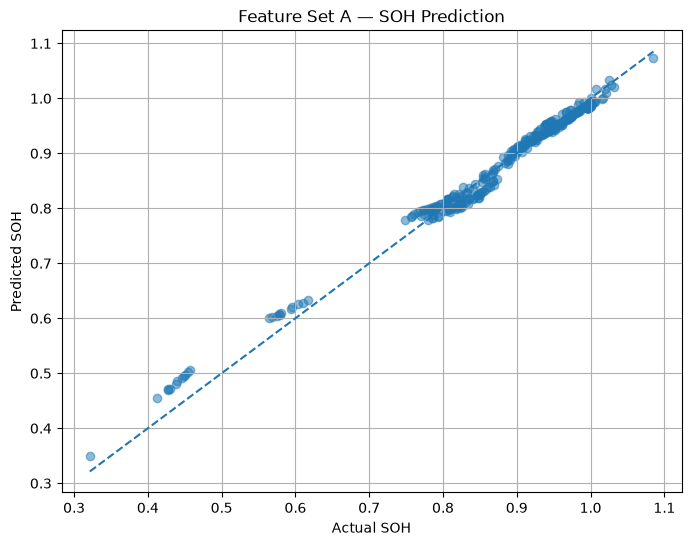

In [112]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_A,
    pred_A,
    alpha=0.5
)

mn = min(y_test_A.min(), pred_A.min())
mx = max(y_test_A.max(), pred_A.max())

plt.plot(
    [mn, mx],
    [mn, mx],
    "--"
)

plt.xlabel("Actual SOH")
plt.ylabel("Predicted SOH")
plt.title("Feature Set A — SOH Prediction")
plt.grid(True)

plt.show()

In [114]:
results_A = test_A[
    ["battery_id", "cycle", "soh"]
].copy()

results_A["predicted_soh"] = pred_A

battery_results_A = []

for battery_id, group in results_A.groupby("battery_id"):

    battery_results_A.append({
        "battery_id": battery_id,
        "MAE": mean_absolute_error(
            group["soh"],
            group["predicted_soh"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                group["soh"],
                group["predicted_soh"]
            )
        ),
        "R2": r2_score(
            group["soh"],
            group["predicted_soh"]
        ),
        "samples": len(group)
    })

battery_results_A = pd.DataFrame(
    battery_results_A
)

battery_results_A

,battery_id,MAE,RMSE,R2,samples
0,B0029,0.005029,0.005949,0.971393,39
1,B0030,0.004720,0.005769,0.972478,39
2,B0038,0.014322,0.016157,0.991137,46
3,B0040,0.020304,0.024892,0.990009,45
4,B0047,0.009675,0.012460,0.972504,68
5,B0054,0.012935,0.014744,0.948077,101


In [118]:
TEST_BATTERIES = [
    "B0029",
    "B0030",
    "B0038",
    "B0040",
    "B0047",
    "B0054"
]

train_C = df_feat[
    ~df_feat["battery_id"].isin(TEST_BATTERIES)
].copy()

test_C = df_feat[
    df_feat["battery_id"].isin(TEST_BATTERIES)
].copy()

print("Training shape:", train_C.shape)
print("Testing shape :", test_C.shape)

Training shape: (2154, 25)
Testing shape : (338, 25)


In [119]:
FEATURES_C = [
    "cycle",
    "capacity_Ah",
    "max_voltage_V",
    "min_voltage_V",
    "mean_voltage_V",
    "max_current_A",
    "min_current_A",
    "mean_current_A",
    "max_temperature_C",
    "min_temperature_C",
    "mean_temperature_C",
    "discharge_time_s",
    "rated_capacity_Ah"
]

X_train_C = train_C[FEATURES_C].copy()
X_test_C  = test_C[FEATURES_C].copy()

y_train_C = train_C["soh"].copy()
y_test_C  = test_C["soh"].copy()

print("Features:", len(FEATURES_C))
print("X_train:", X_train_C.shape)
print("X_test :", X_test_C.shape)

Features: 13
X_train: (2154, 13)
X_test : (338, 13)


In [120]:
print("NaN in training:")
print(X_train_C.isna().sum())

print("\nNaN in testing:")
print(X_test_C.isna().sum())

print("\nInfinite values:")
print(
    np.isinf(
        X_train_C.select_dtypes(include=np.number)
    ).sum().sum()
)

NaN in training:
cycle                 0
capacity_Ah           0
max_voltage_V         0
min_voltage_V         0
mean_voltage_V        0
max_current_A         0
min_current_A         0
mean_current_A        0
max_temperature_C     0
min_temperature_C     0
mean_temperature_C    0
discharge_time_s      0
rated_capacity_Ah     0
dtype: int64

NaN in testing:
cycle                 0
capacity_Ah           0
max_voltage_V         0
min_voltage_V         0
mean_voltage_V        0
max_current_A         0
min_current_A         0
mean_current_A        0
max_temperature_C     0
min_temperature_C     0
mean_temperature_C    0
discharge_time_s      0
rated_capacity_Ah     0
dtype: int64

Infinite values:
0


In [121]:
X_scaler_C = StandardScaler()
y_scaler_C = StandardScaler()

X_train_C_scaled = X_scaler_C.fit_transform(X_train_C)
X_test_C_scaled  = X_scaler_C.transform(X_test_C)

y_train_C_scaled = y_scaler_C.fit_transform(
    y_train_C.to_numpy().reshape(-1, 1)
).ravel()

In [122]:
tf.random.set_seed(42)
np.random.seed(42)

model_C = keras.Sequential([
    layers.Input(
        shape=(X_train_C_scaled.shape[1],)
    ),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.15),

    layers.Dense(32, activation="relu"),

    layers.Dense(16, activation="relu"),

    layers.Dense(1)
])

model_C.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

model_C.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_34 (Dense)                │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,193 (32.00 KB)

 Trainable params: 7,937 (31.00 KB)

 Non-trainable params: 256 (1.00 KB)

In [123]:
history_C = model_C.fit(
    X_train_C_scaled,
    y_train_C_scaled,

    validation_split=0.15,

    epochs=300,
    batch_size=32,

    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=30,
            restore_best_weights=True
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=10,
            min_lr=1e-6
        )
    ],

    verbose=1
)

Epoch 1/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.6959 - mae: 0.6231 - val_loss: 1.5504 - val_mae: 0.7257 - learning_rate: 0.0010
Epoch 2/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2334 - mae: 0.3635 - val_loss: 1.3602 - val_mae: 0.7555 - learning_rate: 0.0010
Epoch 3/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1822 - mae: 0.3208 - val_loss: 1.2903 - val_mae: 0.8798 - learning_rate: 0.0010
Epoch 4/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1431 - mae: 0.2856 - val_loss: 1.1863 - val_mae: 0.9265 - learning_rate: 0.0010
Epoch 5/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1431 - mae: 0.2833 - val_loss: 1.2348 - val_mae: 1.0042 - learning_rate: 0.0010
Epoch 6/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1308 - mae: 0.2704 - val_loss: 1.3352 - val_mae: 1.0791 - learning_rate: 0.0010
Epoch 7/300
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1173 - mae: 0.2604 - val_loss: 1.6847 - val_mae: 1.1937 - learning_rate: 0.0010
Epoch 8/300


In [124]:
pred_C_scaled = model_C.predict(
    X_test_C_scaled,
    verbose=0
).ravel()

pred_C = y_scaler_C.inverse_transform(
    pred_C_scaled.reshape(-1, 1)
).ravel()

print("Prediction completed.")

Prediction completed.


In [125]:
mae_C = mean_absolute_error(
    y_test_C,
    pred_C
)

rmse_C = np.sqrt(
    mean_squared_error(
        y_test_C,
        pred_C
    )
)

r2_C = r2_score(
    y_test_C,
    pred_C
)

print("\n==============================================")
print("FEATURE SET C — CAPACITY + ELECTRICAL + THERMAL")
print("==============================================")

print(f"MAE  : {mae_C:.6f}")
print(f"RMSE : {rmse_C:.6f}")
print(f"R²   : {r2_C:.6f}")


FEATURE SET C — CAPACITY + ELECTRICAL + THERMAL
MAE  : 0.067660
RMSE : 0.100133
R²   : 0.390804


In [126]:
results_C = test_C[
    ["battery_id", "cycle", "soh"]
].copy()

results_C["predicted_soh"] = pred_C

battery_results_C = []

for battery_id, group in results_C.groupby("battery_id"):

    battery_results_C.append({
        "battery_id": battery_id,

        "MAE": mean_absolute_error(
            group["soh"],
            group["predicted_soh"]
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                group["soh"],
                group["predicted_soh"]
            )
        ),

        "R2": r2_score(
            group["soh"],
            group["predicted_soh"]
        ),

        "samples": len(group)
    })

battery_results_C = pd.DataFrame(
    battery_results_C
)

battery_results_C

,battery_id,MAE,RMSE,R2,samples
0,B0029,0.023421,0.028831,0.328183,39
1,B0030,0.019903,0.024837,0.489875,39
2,B0038,0.089765,0.122182,0.493128,46
3,B0040,0.116956,0.185884,0.442859,45
4,B0047,0.074308,0.081865,-0.186962,68
5,B0054,0.066678,0.079306,-0.502138,101


In [128]:
comparison = pd.DataFrame({
    "Model": [
        "DNN - Feature Set A",
        "DNN - Feature Set B",
        "DNN - Feature Set C"
    ],

    "MAE": [
        mae_A,
        mae_B,
        mae_C
    ],

    "RMSE": [
        rmse_A,
        rmse_B,
        rmse_C
    ],

    "R2": [
        r2_A,
        r2_B,
        r2_C
    ]
})

comparison = comparison.sort_values(
    "MAE"
).reset_index(drop=True)

comparison

,Model,MAE,RMSE,R2
0,DNN - Feature Set A,0.011589,0.014904,0.986503
1,DNN - Feature Set C,0.067660,0.100133,0.390804
2,DNN - Feature Set B,0.077236,0.119010,0.139475


In [129]:
ratio_pred = (
    test_A["capacity_Ah"].to_numpy()
    /
    test_A["rated_capacity_Ah"].to_numpy()
)

ratio_mae = mean_absolute_error(
    y_test_A,
    ratio_pred
)

ratio_rmse = np.sqrt(
    mean_squared_error(
        y_test_A,
        ratio_pred
    )
)

ratio_r2 = r2_score(
    y_test_A,
    ratio_pred
)

print("\n================================")
print("DIRECT CAPACITY-RATIO BASELINE")
print("================================")

print(f"MAE  : {ratio_mae:.6f}")
print(f"RMSE : {ratio_rmse:.6f}")
print(f"R²   : {ratio_r2:.6f}")


DIRECT CAPACITY-RATIO BASELINE
MAE  : 0.000000
RMSE : 0.000000
R²   : 1.000000


In [130]:
# ============================================
# CHECK HOW SOH IS DEFINED
# ============================================

df_check = df_feat.copy()

df_check["calculated_soh"] = (
    df_check["capacity_Ah"] /
    df_check["rated_capacity_Ah"]
)

df_check["soh_error"] = (
    df_check["soh"] -
    df_check["calculated_soh"]
)

print("SOH vs Capacity Ratio")
print("================================")

print(
    "Mean absolute difference:",
    df_check["soh_error"].abs().mean()
)

print(
    "Maximum absolute difference:",
    df_check["soh_error"].abs().max()
)

print(
    "RMSE:",
    np.sqrt(
        np.mean(
            df_check["soh_error"] ** 2
        )
    )
)

SOH vs Capacity Ratio
Mean absolute difference: 4.2123429766576464e-17
Maximum absolute difference: 3.3306690738754696e-16
RMSE: 7.931166806690939e-17


In [131]:
print(
    df_check[
        [
            "battery_id",
            "cycle",
            "capacity_Ah",
            "rated_capacity_Ah",
            "soh",
            "calculated_soh",
            "soh_error"
        ]
    ].head(20)
)

   battery_id  cycle  capacity_Ah  rated_capacity_Ah       soh  \
0       B0005      2     1.846327           1.835222  1.006051   
1       B0005      3     1.835349           1.835222  1.000069   
2       B0005      4     1.835263           1.835222  1.000022   
3       B0005      5     1.834646           1.835222  0.999686   
4       B0005      6     1.835662           1.835222  1.000240   
5       B0005      7     1.835146           1.835222  0.999959   
6       B0005      8     1.825757           1.835222  0.994843   
7       B0005      9     1.824774           1.835222  0.994307   
8       B0005     10     1.824613           1.835222  0.994219   
9       B0005     11     1.824620           1.835222  0.994223   
10      B0005     12     1.814202           1.835222  0.988546   
11      B0005     13     1.813752           1.835222  0.988301   
12      B0005     14     1.813440           1.835222  0.988132   
13      B0005     15     1.802598           1.835222  0.982224   
14      B0

In [132]:
ratio_pred = (
    test_A["capacity_Ah"].to_numpy()
    /
    test_A["rated_capacity_Ah"].to_numpy()
)

ratio_mae = mean_absolute_error(
    y_test_A,
    ratio_pred
)

ratio_rmse = np.sqrt(
    mean_squared_error(
        y_test_A,
        ratio_pred
    )
)

ratio_r2 = r2_score(
    y_test_A,
    ratio_pred
)

print("\n================================")
print("DIRECT CAPACITY-RATIO BASELINE")
print("================================")

print(f"MAE  : {ratio_mae:.6f}")
print(f"RMSE : {ratio_rmse:.6f}")
print(f"R²   : {ratio_r2:.6f}")


DIRECT CAPACITY-RATIO BASELINE
MAE  : 0.000000
RMSE : 0.000000
R²   : 1.000000


In [133]:
# ============================================
# SOH GRU — CAPACITY-FREE FEATURES
# ============================================

GRU_FEATURES = [
    "max_voltage_V",
    "min_voltage_V",
    "mean_voltage_V",

    "max_current_A",
    "min_current_A",
    "mean_current_A",

    "max_temperature_C",
    "min_temperature_C",
    "mean_temperature_C",

    "discharge_time_s"
]

TARGET = "soh"

TEST_BATTERIES = [
    "B0029",
    "B0030",
    "B0038",
    "B0040",
    "B0047",
    "B0054"
]

print("GRU features:")
for f in GRU_FEATURES:
    print(" -", f)

print("\nNumber of features:", len(GRU_FEATURES))

GRU features:
 - max_voltage_V
 - min_voltage_V
 - mean_voltage_V
 - max_current_A
 - min_current_A
 - mean_current_A
 - max_temperature_C
 - min_temperature_C
 - mean_temperature_C
 - discharge_time_s

Number of features: 10


In [134]:
gru_df = df_feat[
    ["battery_id", "cycle"] +
    GRU_FEATURES +
    [TARGET]
].copy()

gru_df = gru_df.sort_values(
    ["battery_id", "cycle"]
).reset_index(drop=True)

print("Shape:", gru_df.shape)

print("\nBatteries:",
      gru_df["battery_id"].nunique())

print("\nMissing values:")
print(gru_df.isna().sum())

Shape: (2492, 13)

Batteries: 32

Missing values:
battery_id            0
cycle                 0
max_voltage_V         0
min_voltage_V         0
mean_voltage_V        0
max_current_A         0
min_current_A         0
mean_current_A        0
max_temperature_C     0
min_temperature_C     0
mean_temperature_C    0
discharge_time_s      0
soh                   0
dtype: int64


In [136]:
gru_df = gru_df.replace(
    [np.inf, -np.inf],
    np.nan
)

gru_df = gru_df.dropna(
    subset=GRU_FEATURES + [TARGET]
).reset_index(drop=True)

print("Shape after cleaning:", gru_df.shape)

Shape after cleaning: (2492, 13)


In [137]:
train_gru_df = gru_df[
    ~gru_df["battery_id"].isin(TEST_BATTERIES)
].copy()

test_gru_df = gru_df[
    gru_df["battery_id"].isin(TEST_BATTERIES)
].copy()

print("Training rows:", len(train_gru_df))
print("Testing rows :", len(test_gru_df))

print("\nTraining batteries:",
      train_gru_df["battery_id"].nunique())

print("Testing batteries:",
      test_gru_df["battery_id"].nunique())

print("\nTest batteries:")
print(sorted(test_gru_df["battery_id"].unique()))

Training rows: 2154
Testing rows : 338

Training batteries: 26
Testing batteries: 6

Test batteries:
['B0029', 'B0030', 'B0038', 'B0040', 'B0047', 'B0054']


In [138]:
from sklearn.preprocessing import StandardScaler

feature_scaler_gru = StandardScaler()
target_scaler_gru = StandardScaler()

feature_scaler_gru.fit(
    train_gru_df[GRU_FEATURES]
)

target_scaler_gru.fit(
    train_gru_df[[TARGET]]
)

train_gru_df_scaled = train_gru_df.copy()
test_gru_df_scaled = test_gru_df.copy()

train_gru_df_scaled[GRU_FEATURES] = (
    feature_scaler_gru.transform(
        train_gru_df[GRU_FEATURES]
    )
)

test_gru_df_scaled[GRU_FEATURES] = (
    feature_scaler_gru.transform(
        test_gru_df[GRU_FEATURES]
    )
)

train_gru_df_scaled[TARGET] = (
    target_scaler_gru.transform(
        train_gru_df[[TARGET]]
    ).ravel()
)

test_gru_df_scaled[TARGET] = (
    target_scaler_gru.transform(
        test_gru_df[[TARGET]]
    ).ravel()
)

print("Scaling completed.")

Scaling completed.


In [139]:
SEQUENCE_LENGTH = 10

def create_gru_sequences(dataframe, sequence_length):

    X = []
    y = []
    battery_ids = []
    target_cycles = []

    for battery_id, group in dataframe.groupby(
        "battery_id"
    ):

        group = group.sort_values("cycle").reset_index(
            drop=True
        )

        features = group[GRU_FEATURES].to_numpy(
            dtype=np.float32
        )

        targets = group[TARGET].to_numpy(
            dtype=np.float32
        )

        cycles = group["cycle"].to_numpy()

        for i in range(
            sequence_length - 1,
            len(group)
        ):

            sequence = features[
                i - sequence_length + 1 : i + 1
            ]

            X.append(sequence)

            y.append(targets[i])

            battery_ids.append(battery_id)

            target_cycles.append(cycles[i])

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32),
        np.array(battery_ids),
        np.array(target_cycles)
    )

In [140]:
X_train_gru, y_train_gru, train_ids_gru, train_cycles_gru = \
    create_gru_sequences(
        train_gru_df_scaled,
        SEQUENCE_LENGTH
    )

print("X_train shape:", X_train_gru.shape)
print("y_train shape:", y_train_gru.shape)

X_train shape: (1920, 10, 10)
y_train shape: (1920,)


In [141]:
X_test_gru, y_test_gru, test_ids_gru, test_cycles_gru = \
    create_gru_sequences(
        test_gru_df_scaled,
        SEQUENCE_LENGTH
    )

print("X_test shape:", X_test_gru.shape)
print("y_test shape:", y_test_gru.shape)

print("\nTest batteries represented:")
print(np.unique(test_ids_gru))

X_test shape: (284, 10, 10)
y_test shape: (284,)

Test batteries represented:
['B0029' 'B0030' 'B0038' 'B0040' 'B0047' 'B0054']


In [143]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    gss.split(
        X_train_gru,
        y_train_gru,
        groups=train_ids_gru
    )
)

X_tr = X_train_gru[train_idx]
X_val = X_train_gru[val_idx]

y_tr = y_train_gru[train_idx]
y_val = y_train_gru[val_idx]

print("Training sequences  :", X_tr.shape)
print("Validation sequences:", X_val.shape)

print("\nValidation batteries:")
print(
    sorted(
        np.unique(
            train_ids_gru[val_idx]
        )
    )
)

Training sequences  : (1368, 10, 10)
Validation sequences: (552, 10, 10)

Validation batteries:
[np.str_('B0005'), np.str_('B0031'), np.str_('B0032'), np.str_('B0034'), np.str_('B0043'), np.str_('B0055')]


In [144]:
tf.random.set_seed(42)
np.random.seed(42)

model_gru = keras.Sequential([

    layers.Input(
        shape=(
            SEQUENCE_LENGTH,
            len(GRU_FEATURES)
        )
    ),

    layers.GRU(
        64,
        return_sequences=True
    ),

    layers.Dropout(0.15),

    layers.GRU(
        32
    ),

    layers.Dense(
        32,
        activation="relu"
    ),

    layers.Dense(
        16,
        activation="relu"
    ),

    layers.Dense(1)
])

model_gru.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="mse",

    metrics=["mae"]
)

model_gru.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 10, 64)         │        14,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,601 (100.00 KB)

 Trainable params: 25,601 (100.00 KB)

 Non-trainable params: 0 (0.00 B)

In [145]:
callbacks_gru = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=25,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-6
    )
]

history_gru = model_gru.fit(

    X_tr,
    y_tr,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=300,

    batch_size=32,

    callbacks=callbacks_gru,

    verbose=1
)

Epoch 1/300
43/43 ━━━━━━━━━━━━━━━━━━━━ 34s 43ms/step - loss: 0.7371 - mae: 0.6312 - val_loss: 0.3926 - val_mae: 0.5083 - learning_rate: 0.0010
Epoch 2/300
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3744 - mae: 0.4100 - val_loss: 0.2864 - val_mae: 0.4179 - learning_rate: 0.0010
Epoch 3/300
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.2651 - mae: 0.3387 - val_loss: 0.3787 - val_mae: 0.4721 - learning_rate: 0.0010
Epoch 4/300
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1884 - mae: 0.2890 - val_loss: 0.4853 - val_mae: 0.5518 - learning_rate: 0.0010
Epoch 5/300
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1528 - mae: 0.2600 - val_loss: 0.5736 - val_mae: 0.6480 - learning_rate: 0.0010
Epoch 6/300
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1581 - mae: 0.2534 - val_loss: 0.3780 - val_mae: 0.5320 - learning_rate: 0.0010
Epoch 7/300
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.1501 - mae: 0.2468 - val_loss: 0.6578 - val_mae: 0.6738 - learning_rate: 0.0010
Epoch

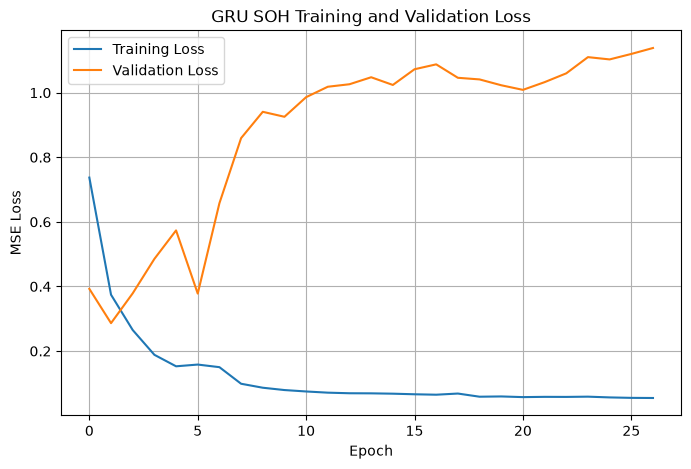

In [146]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_gru.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_gru.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "GRU SOH Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.show()

In [147]:
pred_gru_scaled = model_gru.predict(
    X_test_gru,
    verbose=0
).ravel()

pred_gru = target_scaler_gru.inverse_transform(
    pred_gru_scaled.reshape(-1, 1)
).ravel()

actual_gru = target_scaler_gru.inverse_transform(
    y_test_gru.reshape(-1, 1)
).ravel()

print("Prediction completed.")

Prediction completed.


In [148]:
mae_gru = mean_absolute_error(
    actual_gru,
    pred_gru
)

rmse_gru = np.sqrt(
    mean_squared_error(
        actual_gru,
        pred_gru
    )
)

r2_gru = r2_score(
    actual_gru,
    pred_gru
)

print("\n======================================")
print("CAPACITY-FREE GRU — SOH")
print("======================================")

print(f"MAE  : {mae_gru:.6f}")
print(f"RMSE : {rmse_gru:.6f}")
print(f"R²   : {r2_gru:.6f}")


CAPACITY-FREE GRU — SOH
MAE  : 0.060223
RMSE : 0.083910
R²   : 0.213619


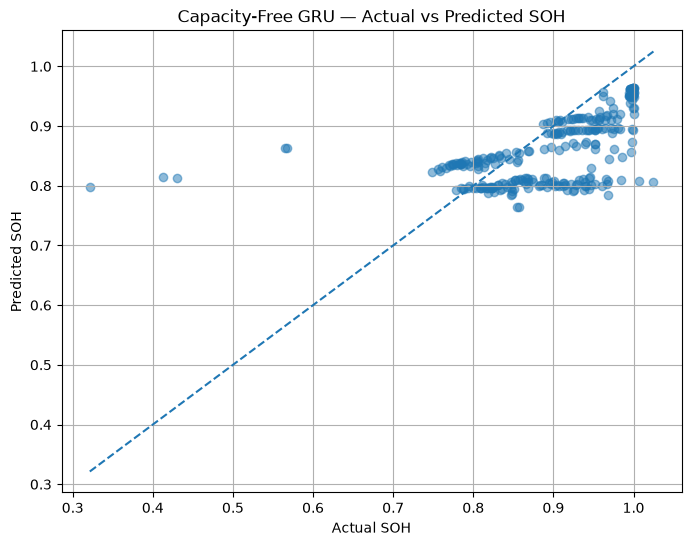

In [149]:
plt.figure(figsize=(8, 6))

plt.scatter(
    actual_gru,
    pred_gru,
    alpha=0.5
)

mn = min(
    actual_gru.min(),
    pred_gru.min()
)

mx = max(
    actual_gru.max(),
    pred_gru.max()
)

plt.plot(
    [mn, mx],
    [mn, mx],
    "--"
)

plt.xlabel("Actual SOH")
plt.ylabel("Predicted SOH")

plt.title(
    "Capacity-Free GRU — Actual vs Predicted SOH"
)

plt.grid(True)

plt.show()

In [150]:
gru_results = pd.DataFrame({
    "battery_id": test_ids_gru,
    "cycle": test_cycles_gru,
    "actual_soh": actual_gru,
    "predicted_soh": pred_gru
})

per_battery_gru = []

for battery_id, group in gru_results.groupby(
    "battery_id"
):

    mae = mean_absolute_error(
        group["actual_soh"],
        group["predicted_soh"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            group["actual_soh"],
            group["predicted_soh"]
        )
    )

    r2 = r2_score(
        group["actual_soh"],
        group["predicted_soh"]
    )

    per_battery_gru.append({
        "battery_id": battery_id,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "samples": len(group)
    })

per_battery_gru = pd.DataFrame(
    per_battery_gru
)

per_battery_gru

,battery_id,MAE,RMSE,R2,samples
0,B0029,0.028597,0.035207,-0.659460,30
1,B0030,0.041894,0.048122,-2.279471,30
2,B0038,0.081475,0.103182,-0.068393,37
3,B0040,0.076998,0.132270,0.378467,36
4,B0047,0.040911,0.046335,0.255634,59
5,B0054,0.073786,0.089838,-1.660290,92


In [151]:
gru_results = pd.DataFrame({
    "battery_id": test_ids_gru,
    "cycle": test_cycles_gru,
    "actual_soh": actual_gru,
    "predicted_soh": pred_gru
})

per_battery_gru = []

for battery_id, group in gru_results.groupby(
    "battery_id"
):

    mae = mean_absolute_error(
        group["actual_soh"],
        group["predicted_soh"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            group["actual_soh"],
            group["predicted_soh"]
        )
    )

    r2 = r2_score(
        group["actual_soh"],
        group["predicted_soh"]
    )

    per_battery_gru.append({
        "battery_id": battery_id,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "samples": len(group)
    })

per_battery_gru = pd.DataFrame(
    per_battery_gru
)

per_battery_gru

,battery_id,MAE,RMSE,R2,samples
0,B0029,0.028597,0.035207,-0.659460,30
1,B0030,0.041894,0.048122,-2.279471,30
2,B0038,0.081475,0.103182,-0.068393,37
3,B0040,0.076998,0.132270,0.378467,36
4,B0047,0.040911,0.046335,0.255634,59
5,B0054,0.073786,0.089838,-1.660290,92


In [152]:
final_comparison = pd.DataFrame({

    "Model": [
        "DNN - Feature Set A",
        "DNN - Feature Set B",
        "DNN - Feature Set C",
        "GRU - Capacity Free"
    ],

    "MAE": [
        mae_A,
        mae_B,
        mae_C,
        mae_gru
    ],

    "RMSE": [
        rmse_A,
        rmse_B,
        rmse_C,
        rmse_gru
    ],

    "R2": [
        r2_A,
        r2_B,
        r2_C,
        r2_gru
    ]
})

final_comparison

,Model,MAE,RMSE,R2
0,DNN - Feature Set A,0.011589,0.014904,0.986503
1,DNN - Feature Set B,0.077236,0.119010,0.139475
2,DNN - Feature Set C,0.067660,0.100133,0.390804
3,GRU - Capacity Free,0.060223,0.083910,0.213619


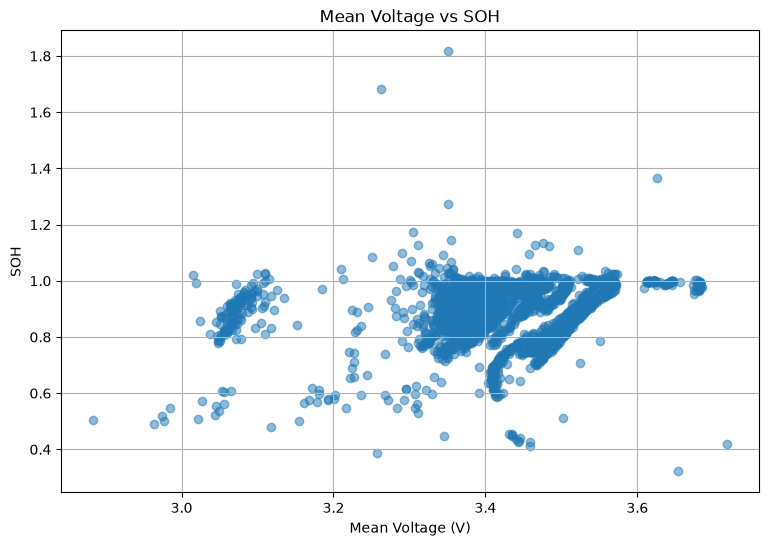

In [153]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    df["mean_voltage_V"],
    df["soh"],
    alpha=0.5
)

plt.xlabel("Mean Voltage (V)")
plt.ylabel("SOH")
plt.title("Mean Voltage vs SOH")
plt.grid(True)

plt.show()

In [154]:
VOLTAGE_FEATURES = [
    "max_voltage_V",
    "min_voltage_V",
    "mean_voltage_V"
]

TARGET = "soh"

In [155]:
df = df.sort_values(["battery_id", "cycle"]).reset_index(drop=True)

print(df[VOLTAGE_FEATURES + [TARGET]].describe())

       max_voltage_V  min_voltage_V  mean_voltage_V          soh
count    2524.000000    2524.000000     2524.000000  2524.000000
mean        4.186738       2.323147        3.414459     0.887453
std         0.027364       0.285072        0.117043     0.107518
min         3.800033       1.193246        2.883240     0.321313
25%         4.182156       2.071378        3.367918     0.829714
50%         4.187051       2.386750        3.412324     0.905728
75%         4.197671       2.627129        3.478143     0.967074
max         4.519252       2.699983        3.717995     1.815976


In [156]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        df[VOLTAGE_FEATURES],
        df[TARGET],
        groups=df["battery_id"]
    )
)

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

print("Training batteries:")
print(sorted(train_df["battery_id"].unique()))

print("\nTesting batteries:")
print(sorted(test_df["battery_id"].unique()))

Training batteries:
['B0005', 'B0006', 'B0007', 'B0018', 'B0025', 'B0026', 'B0027', 'B0028', 'B0031', 'B0032', 'B0033', 'B0034', 'B0036', 'B0039', 'B0041', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0048', 'B0049', 'B0051', 'B0053', 'B0056']

Testing batteries:
['B0029', 'B0030', 'B0038', 'B0040', 'B0047', 'B0054', 'B0055']


In [157]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X_train = train_df[VOLTAGE_FEATURES]
X_test = test_df[VOLTAGE_FEATURES]

y_train = train_df[TARGET]
y_test = test_df[TARGET]

rf_voltage = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_voltage.fit(X_train, y_train)

pred_voltage = rf_voltage.predict(X_test)

mae = mean_absolute_error(y_test, pred_voltage)
rmse = np.sqrt(mean_squared_error(y_test, pred_voltage))
r2 = r2_score(y_test, pred_voltage)

print("=" * 45)
print("VOLTAGE-ONLY RANDOM FOREST")
print("=" * 45)
print(f"MAE  : {mae:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")

VOLTAGE-ONLY RANDOM FOREST
MAE  : 0.078050
RMSE : 0.127141
R²   : -0.124257


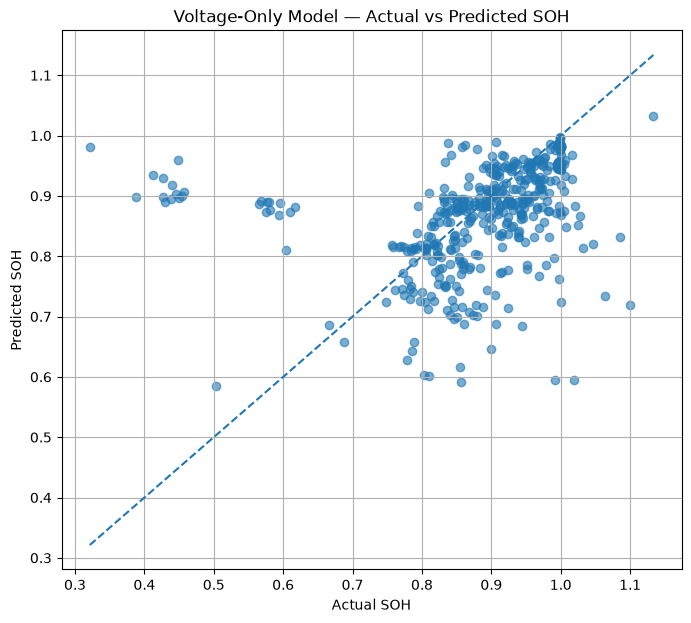

In [158]:
plt.figure(figsize=(8, 7))

plt.scatter(
    y_test,
    pred_voltage,
    alpha=0.6
)

min_val = min(y_test.min(), pred_voltage.min())
max_val = max(y_test.max(), pred_voltage.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "--"
)

plt.xlabel("Actual SOH")
plt.ylabel("Predicted SOH")
plt.title("Voltage-Only Model — Actual vs Predicted SOH")
plt.grid(True)

plt.show()

In [159]:
VOLTAGE_CYCLE_FEATURES = [
    "cycle",
    "max_voltage_V",
    "min_voltage_V",
    "mean_voltage_V"
]

X_train = train_df[VOLTAGE_CYCLE_FEATURES]
X_test = test_df[VOLTAGE_CYCLE_FEATURES]

y_train = train_df["soh"]
y_test = test_df["soh"]

rf_voltage_cycle = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_voltage_cycle.fit(X_train, y_train)

pred_vc = rf_voltage_cycle.predict(X_test)

mae_vc = mean_absolute_error(y_test, pred_vc)
rmse_vc = np.sqrt(mean_squared_error(y_test, pred_vc))
r2_vc = r2_score(y_test, pred_vc)

print("=" * 50)
print("VOLTAGE + CYCLE RANDOM FOREST")
print("=" * 50)
print(f"MAE  : {mae_vc:.6f}")
print(f"RMSE : {rmse_vc:.6f}")
print(f"R²   : {r2_vc:.6f}")

VOLTAGE + CYCLE RANDOM FOREST
MAE  : 0.062753
RMSE : 0.119174
R²   : 0.012220


In [160]:
VCURRENT_FEATURES = [
    "cycle",
    
    "max_voltage_V",
    "min_voltage_V",
    "mean_voltage_V",
    
    "max_current_A",
    "min_current_A",
    "mean_current_A"
]

X_train_vc = train_df[VCURRENT_FEATURES].copy()
X_test_vc  = test_df[VCURRENT_FEATURES].copy()

y_train_vc = train_df["soh"].copy()
y_test_vc  = test_df["soh"].copy()


rf_vcurrent = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_vcurrent.fit(X_train_vc, y_train_vc)

pred_vcurrent = rf_vcurrent.predict(X_test_vc)


mae_vcurrent = mean_absolute_error(y_test_vc, pred_vcurrent)
rmse_vcurrent = np.sqrt(mean_squared_error(y_test_vc, pred_vcurrent))
r2_vcurrent = r2_score(y_test_vc, pred_vcurrent)

print("=" * 55)
print("VOLTAGE + CURRENT + CYCLE RANDOM FOREST")
print("=" * 55)

print(f"MAE  : {mae_vcurrent:.6f}")
print(f"RMSE : {rmse_vcurrent:.6f}")
print(f"R²   : {r2_vcurrent:.6f}")

VOLTAGE + CURRENT + CYCLE RANDOM FOREST
MAE  : 0.076324
RMSE : 0.130201
R²   : -0.179031
